# Hotel bookings dashboard: data, charts and export

**Data sources:** `data/processed/hotel_bookings_clean.csv` (cleaned in Part 1 from Antonio, N., de Almeida, A. and Nunes, L. (2019), *Hotel booking demand datasets*, Data in Brief, 22, 41–49, https://doi.org/10.1016/j.dib.2018.11.126) `data/processed/country_names.csv` (Part 3, ISO 3166 names from pycountry) and `data/external/world-110m.json` (world map at 1:110 million, TopoJSON World Atlas from Natural Earth, public domain, copied from the npm package vega-datasets 3.2.1).
**Date:** 2026-11-05
**Authors:** Group 3, Presentation and Visualization (Infovis2627)
**Description:** This notebook builds the two-screen dashboard of Part 6 for the persona Natalia, a tourism analyst: it prepares small aggregated tables with pandas, builds every chart with Vega-Altair, and writes `data.js` and `specs.js` straight into `../dashboard/`. It answers the seven questions of Part 2 (main screen: Q1, Q5, Q7; detail screen: Q2, Q3, Q4, Q6).

---

## Contents

1. [Data loading](#1.-Data-loading)
2. [Initial exploration](#2.-Initial-exploration)
3. [Cleaning and preparation: aggregated tables](#3.-Cleaning-and-preparation:-aggregated-tables)
4. [Analysis: checks of the tables](#4.-Analysis:-checks-of-the-tables)
5. [Accessible visualisation: the charts](#5.-Accessible-visualisation:-the-charts)
6. [Export](#6.-Export)
7. [Conclusions](#Conclusions)

In [1]:
# ── Imports ──────────────────────────────────────────────────────────────────
import calendar
import json
import re
import sys
import warnings
from decimal import Decimal, ROUND_HALF_UP
from pathlib import Path

import pandas as pd
import altair as alt
import pycountry
import vl_convert as vlc     # renders the Vega-Lite specs to SVG, to check what the charts draw
from IPython.display import SVG

# Global Altair configuration (jupyter-accessible-notebook and wcag-accessibility skills)
alt.data_transformers.disable_max_rows()   # kept as the skill asks; only aggregated tables are charted
alt.renderers.enable('svg')                # SVG, never canvas

# Paths
CLEAN_FILE    = Path('../../data/processed/hotel_bookings_clean.csv')
NAMES_FILE    = Path('../../data/processed/country_names.csv')
WORLD_FILE    = Path('../../data/external/world-110m.json')    # world map (TopoJSON), vega-datasets 3.2.1
PROCESSED_DIR = Path('../../data/processed')
DASHBOARD_DIR = Path('../dashboard')
OUTPUT_DIR    = Path('build_dashboard_output')
for folder in [PROCESSED_DIR, DASHBOARD_DIR, OUTPUT_DIR]:
    folder.mkdir(parents=True, exist_ok=True)

SEED = 112358   # fixed seed of the project; this notebook has no randomness, so it is not used

print('Python', sys.version.split()[0], '| pandas', pd.__version__, '| altair', alt.__version__,
      '| Vega-Lite', alt.SCHEMA_VERSION, '| vl-convert', vlc.__version__,
      '| pycountry', pycountry.__version__ if hasattr(pycountry, '__version__') else '26.2.16')

Python 3.13.18 | pandas 3.0.5 | altair 6.2.2 | Vega-Lite v6.4.1 | vl-convert 1.9.0 | pycountry 26.2.16


## 1. Data loading

In [2]:
# ── Load the cleaned bookings and add the country names ──────────────────────
bookings = pd.read_csv(CLEAN_FILE, keep_default_na=False)
names = pd.read_csv(NAMES_FILE, keep_default_na=False)
bookings = bookings.merge(names[['country', 'country_name']], on='country', how='left', validate='many_to_one')

# Date fields used by the dashboard
bookings['arrival_date'] = pd.to_datetime(bookings['arrival_date'])
bookings['arrival_month'] = bookings['arrival_date'].dt.to_period('M').dt.to_timestamp()
bookings['year'] = bookings['arrival_date'].dt.year
bookings['calendar_month'] = bookings['arrival_date'].dt.month

print(f'Rows: {len(bookings):,} | columns: {bookings.shape[1]} | bookings without a country name: {bookings["country_name"].isna().sum()}')
bookings[['hotel', 'arrival_month', 'country_name', 'is_canceled', 'total_guests', 'total_nights', 'lead_time', 'adr']].head()

Rows: 119,201 | columns: 39 | bookings without a country name: 0


,hotel,arrival_month,country_name,is_canceled,total_guests,total_nights,lead_time,adr
0,Resort Hotel,2015-07-01,Portugal,0,2,0,342,0.0
1,Resort Hotel,2015-07-01,Portugal,0,2,0,737,0.0
2,Resort Hotel,2015-07-01,United Kingdom,0,1,1,7,75.0
3,Resort Hotel,2015-07-01,United Kingdom,0,1,1,13,75.0
4,Resort Hotel,2015-07-01,United Kingdom,0,2,2,14,98.0


### Decision: what is a "stay", a "guest" and a "visitor"

**Context:** the dashboard counts bookings, but Natalia's questions are about people who came.

**Decision taken:** a **stay** is a booking that was not cancelled (`is_canceled` = 0); **guests** (visitors) are the people of those stays (`total_guests`); the **cancellation rate** uses all bookings. Prices are the median `adr` of stays with a price above 0, as in Part 1. The **top 10 countries** are the ten with the most guests over both hotels and the whole period (students' decision before task 6.1); every other country, and the bookings without a country ("Unknown"), form "Other".

> ⚠️ **Limitation:** duplicated rows are kept (cleaning rule 1), so some counts and Portugal's cancellation rate are inflated; the dashboard shows a note.

## 2. Initial exploration

In [3]:
# ── The numbers every table must add up to ───────────────────────────────────
stays = bookings[bookings['is_canceled'] == 0]
paid_stays = stays[stays['adr'] > 0]

totals = pd.Series({
    'bookings': len(bookings),
    'cancelled bookings': int(bookings['is_canceled'].sum()),
    'stays': len(stays),
    'guests of stays': int(stays['total_guests'].sum()),
    'paid stays (price above 0)': len(paid_stays),
}, name='total')
totals

bookings                      119201
cancelled bookings             44194
stays                          75007
guests of stays               145980
paid stays (price above 0)     73385
Name: total, dtype: int64

In [4]:
# ── Top 10 countries by guests (both hotels, whole period) ───────────────────
guests_by_country = stays.groupby('country_name')['total_guests'].sum().sort_values(ascending=False)
TOP_10 = guests_by_country.drop('Unknown', errors='ignore').head(10).index.tolist()
top_10_table = guests_by_country.loc[TOP_10].rename('guests').to_frame()
top_10_table['% of all guests'] = (100 * top_10_table['guests'] / totals['guests of stays']).round(1)
print(f"Top 10 together: {top_10_table['% of all guests'].sum():.1f} % of all guests")
top_10_table

Top 10 together: 82.0 % of all guests


,guests,% of all guests
country_name,,
Portugal,37655,25.8
United Kingdom,19246,13.2
France,17299,11.9
Spain,13213,9.1
Germany,11659,8.0
Ireland,5102,3.5
Italy,4894,3.4
Belgium,3855,2.6
Netherlands,3374,2.3


**Finding:** the ten countries hold 82.0 % of all guests, so "Other" is a single, modest group. Portugal is still first, but with 25.8 % of guests instead of the 40.7 % of bookings seen in Part 1: many Portuguese bookings were cancelled, so counting visitors instead of bookings changes the picture.

## 3. Cleaning and preparation: aggregated tables

No raw row is charted (architecture.md). Six small tables are made with pandas, at the level the Part 5 interactions need:

| Table | Level | Used by |
|---|---|---|
| `month_hotel` | arrival month × hotel | C1, C2, C3 (filters I1, I2; month highlight I5) |
| `country_hotel` | country group (and each other country with enough stays) × hotel × year | C4 (filters, country selection I7, sort I9) |
| `country_map` | country (ISO) × hotel × year | C5 map |
| `filter_kpis` | each hotel filter × year filter (12 combinations) | KPIs of both screens |
| `country_medians` | country group (and each other country) × hotel filter × year filter | C7, C8 (box plots) and the selected-country KPIs |
| `country_season` | country group (and each other country) × hotel filter × year filter × calendar month | C9 (animated bubbles) |

The charts show the **top 10 countries and Other**; any other country with at least 20 stays can be chosen in the page's list of countries, and it then appears at the top of the charts (students' decision when the dashboard was refined), so the tables also hold one row per such country, marked `in_top = False`.

Sums and counts can be added up by the charts after filtering; **medians and quartiles cannot**, so they are computed here for every filter combination.

In [5]:
# ── Filter combinations of the dashboard (I1 hotel x I2 year) ────────────────
HOTEL_FILTERS = ['Both', 'City Hotel', 'Resort Hotel']
YEAR_FILTERS = ['All', 2015, 2016, 2017]

def filtered(table, hotel_filter, year_filter):
    """Rows of a table that a given hotel filter and year filter keep."""
    keep = pd.Series(True, index=table.index)
    if hotel_filter != 'Both':
        keep &= table['hotel'] == hotel_filter
    if year_filter != 'All':
        keep &= table['year'] == year_filter
    return table[keep]

# Country group: one of the top 10, or Other (all other countries and 'Unknown')
for table in [bookings]:
    table['country_group'] = table['country_name'].where(table['country_name'].isin(TOP_10), 'Other')
stays = bookings[bookings['is_canceled'] == 0]
paid_stays = stays[stays['adr'] > 0]

# Countries outside the top 10 that the page lets Natalia choose: at least 20 stays (both hotels, all years),
# the same minimum as the bubbles of C9, so their medians are not built on a handful of stays
MIN_STAYS = 20
stays_per_country = stays[~stays['country_name'].isin(TOP_10 + ['Unknown'])].groupby('country_name').size()
MORE_COUNTRIES = sorted(stays_per_country[stays_per_country >= MIN_STAYS].index)
SELECTABLE = [(name, True) for name in TOP_10 + ['Other']] + [(name, False) for name in MORE_COUNTRIES]   # (name, in_top)


def rows_of(table, name, in_top):
    """Rows of a table for a country group (top 10 or Other) or for one country of the list."""
    return table[table['country_group'] == name] if in_top else table[table['country_name'] == name]


print('Filter combinations:', len(HOTEL_FILTERS) * len(YEAR_FILTERS), '| country groups:', bookings['country_group'].nunique(),
      f'| other countries with at least {MIN_STAYS} stays (in the list): {len(MORE_COUNTRIES)}')

Filter combinations: 12 | country groups: 11 | other countries with at least 20 stays (in the list): 53


In [6]:
# ── Table 1: month x hotel (C1 guests, C2 cancellation rate, C3 median price) ─
month_hotel = (bookings.groupby(['arrival_month', 'hotel'])
               .agg(bookings=('is_canceled', 'size'), cancelled=('is_canceled', 'sum'))
               .join(stays.groupby(['arrival_month', 'hotel']).agg(stays=('is_canceled', 'size'), guests=('total_guests', 'sum')))
               .join(paid_stays.groupby(['arrival_month', 'hotel']).agg(median_price=('adr', 'median')))
               .reset_index())
month_hotel['year'] = month_hotel['arrival_month'].dt.year
month_hotel['cancel_rate'] = (100 * month_hotel['cancelled'] / month_hotel['bookings']).round(1)
month_hotel['median_price'] = month_hotel['median_price'].round(1)
print(f'month_hotel: {len(month_hotel)} rows')
month_hotel.head()

month_hotel: 52 rows


,arrival_month,hotel,bookings,cancelled,stays,guests,median_price,year,cancel_rate
0,2015-07-01,City Hotel,1396,939,457,852,80.0,2015,67.3
1,2015-07-01,Resort Hotel,1377,320,1057,2318,123.0,2015,23.2
2,2015-08-01,City Hotel,2470,1228,1242,2451,81.0,2015,49.7
3,2015-08-01,Resort Hotel,1409,366,1043,2344,153.4,2015,26.0
4,2015-09-01,City Hotel,3524,1542,1982,3456,100.6,2015,43.8


In [7]:
# ── Table 2: guests per country group (and per country of the list) x hotel x year (C4) ─
hotel_rows = []
for name, in_top in SELECTABLE:
    for (hotel, year), group in rows_of(bookings, name, in_top).groupby(['hotel', 'year']):
        hotel_rows.append({'country_group': name, 'in_top': in_top, 'hotel': hotel, 'year': int(year),
                           'bookings': len(group), 'guests': int(group.loc[group['is_canceled'] == 0, 'total_guests'].sum())})
country_hotel = pd.DataFrame(hotel_rows)
print(f'country_hotel: {len(country_hotel)} rows ({country_hotel["in_top"].sum()} for the top 10 and Other)')
country_hotel.head()

country_hotel: 360 rows (66 for the top 10 and Other)


,country_group,in_top,hotel,year,bookings,guests
0,Portugal,True,City Hotel,2015,8949,5512
1,Portugal,True,City Hotel,2016,13984,9252
2,Portugal,True,City Hotel,2017,7922,4044
3,Portugal,True,Resort Hotel,2015,4336,4863
4,Portugal,True,Resort Hotel,2016,8289,8546


In [8]:
# ── Table 3: country x hotel x year for the map (C5), with the ISO numeric code ─

def iso_numeric(alpha_3):
    """ISO 3166 numeric code of a three-letter code (current or former), as used by world maps."""
    country = pycountry.countries.get(alpha_3=alpha_3)
    if country is None:
        country = next((old for old in pycountry.historic_countries if getattr(old, 'alpha_3', None) == alpha_3), None)
    return int(country.numeric) if country is not None and getattr(country, 'numeric', None) else None

country_map = (stays[stays['country'] != 'Unknown']
               .groupby(['country', 'country_name', 'hotel', 'year'])
               .agg(guests=('total_guests', 'sum')).reset_index())
country_map['iso_numeric'] = country_map['country'].map(iso_numeric)
print(f'country_map: {len(country_map)} rows | codes without a numeric code: '
      f'{sorted(country_map.loc[country_map["iso_numeric"].isna(), "country"].unique())}')
country_map.head()

country_map: 586 rows | codes without a numeric code: []


,country,country_name,hotel,year,guests,iso_numeric
0,ABW,Aruba,City Hotel,2016,3,533
1,ABW,Aruba,City Hotel,2017,2,533
2,AGO,Angola,City Hotel,2015,72,24
3,AGO,Angola,City Hotel,2016,88,24
4,AGO,Angola,City Hotel,2017,87,24


In [9]:
# ── Table 4: KPIs for each filter combination ─────────────────────────────────
kpi_rows = []
for hotel_filter in HOTEL_FILTERS:
    for year_filter in YEAR_FILTERS:
        all_rows = filtered(bookings, hotel_filter, year_filter)
        stay_rows = filtered(stays, hotel_filter, year_filter)
        paid_rows = filtered(paid_stays, hotel_filter, year_filter)
        guests_per_country = stay_rows[stay_rows['country'] != 'Unknown'].groupby('country_name')['total_guests'].sum()
        kpi_rows.append({
            'hotel_filter': hotel_filter, 'year_filter': str(year_filter),
            'bookings': len(all_rows), 'stays': len(stay_rows), 'guests': int(stay_rows['total_guests'].sum()),
            'cancel_rate': round(100 * all_rows['is_canceled'].mean(), 1),
            'median_price': round(paid_rows['adr'].median(), 1),
            'countries_of_origin': int((guests_per_country > 0).sum()),
            'largest_market': guests_per_country.idxmax(),
            'largest_market_share': round(100 * guests_per_country.max() / stay_rows['total_guests'].sum(), 1),
        })
filter_kpis = pd.DataFrame(kpi_rows)
filter_kpis

,hotel_filter,year_filter,bookings,stays,guests,cancel_rate,median_price,countries_of_origin,largest_market,largest_market_share
0,Both,All,119201,75007,145980,37.1,94.5,165,Portugal,25.8
1,Both,2015,21961,13824,25931,37.1,85.0,98,Portugal,40.0
2,Both,2016,56621,36298,70852,35.9,91.0,136,Portugal,25.1
3,Both,2017,40619,24885,49197,38.7,105.0,134,Portugal,19.3
4,City Hotel,All,79156,46082,89434,41.8,100.3,150,Portugal,21.0
5,City Hotel,2015,13653,7654,13729,43.9,85.7,86,Portugal,40.1
6,City Hotel,2016,38057,22662,44421,40.5,99.5,125,Portugal,20.8
7,City Hotel,2017,27446,15766,31284,42.6,112.7,125,France,16.5
8,Resort Hotel,All,40045,28925,56546,27.8,74.0,118,Portugal,33.3
9,Resort Hotel,2015,8308,6170,12202,25.7,77.4,71,Portugal,39.9


In [10]:
# ── Table 5: medians, quartiles and rates per country group for each filter combination ─
# The box plots (C7, C8) need the quartiles and the whiskers of the nights and the booking advance.
# Whiskers follow Tukey's rule: the furthest stay that is within 1.5 times the box length (IQR) of the box.

def box_numbers(values, prefix):
    """Median, quartiles and Tukey whiskers of a column of stays, with names that start with prefix."""
    if len(values) == 0:
        return {f'{prefix}_{name}': None for name in ['low', 'q1', 'median', 'q3', 'high']}
    q1, median, q3 = values.quantile([0.25, 0.5, 0.75])
    reach = 1.5 * (q3 - q1)
    return {f'{prefix}_low': float(values[values >= q1 - reach].min()), f'{prefix}_q1': float(q1),
            f'{prefix}_median': float(median), f'{prefix}_q3': float(q3),
            f'{prefix}_high': float(values[values <= q3 + reach].max())}


median_rows = []
for hotel_filter in HOTEL_FILTERS:
    for year_filter in YEAR_FILTERS:
        all_rows = filtered(bookings, hotel_filter, year_filter)
        stay_rows = filtered(stays, hotel_filter, year_filter)
        for group, in_top in SELECTABLE:
            group_all = rows_of(all_rows, group, in_top)
            group_stays = rows_of(stay_rows, group, in_top)
            enough = in_top or len(group_stays) >= MIN_STAYS     # box plots of a country of the list need 20 stays
            median_rows.append({
                'hotel_filter': hotel_filter, 'year_filter': str(year_filter), 'country_group': group, 'in_top': in_top,
                'guests': int(group_stays['total_guests'].sum()),
                'bookings': len(group_all),
                'cancel_rate': round(100 * group_all['is_canceled'].mean(), 1) if len(group_all) else None,
                'median_nights': group_stays['total_nights'].median() if len(group_stays) else None,
                'median_lead_time': group_stays['lead_time'].median() if len(group_stays) else None,
                **box_numbers(group_stays['total_nights'] if enough else group_stays['total_nights'].iloc[:0], 'nights'),
                **box_numbers(group_stays['lead_time'] if enough else group_stays['lead_time'].iloc[:0], 'lead'),
            })
country_medians = pd.DataFrame(median_rows)
print(f'country_medians: {len(country_medians)} rows')
country_medians[(country_medians['hotel_filter'] == 'Both') & (country_medians['year_filter'] == 'All') & country_medians['in_top']]

country_medians: 768 rows


,hotel_filter,year_filter,country_group,in_top,guests,bookings,cancel_rate,median_nights,median_lead_time,nights_low,nights_q1,nights_median,nights_q3,nights_high,lead_low,lead_q1,lead_median,lead_q3,lead_high
0,Both,All,Portugal,True,37655,48476,56.7,2.0,13.0,0.0,1.0,2.0,3.0,6.0,0.0,2.0,13.0,69.00,169.0
1,Both,All,United Kingdom,True,19246,12118,20.2,4.0,98.0,0.0,3.0,4.0,7.0,13.0,0.0,32.0,98.0,194.00,434.0
2,Both,All,France,True,17299,10401,18.6,3.0,53.0,0.0,2.0,3.0,4.0,7.0,0.0,17.0,53.0,116.00,264.0
3,Both,All,Spain,True,13213,8560,25.4,3.0,25.0,0.0,2.0,3.0,4.0,7.0,0.0,6.0,25.0,62.00,146.0
4,Both,All,Germany,True,11659,7285,16.7,3.0,108.0,1.0,2.0,3.0,4.0,7.0,0.0,37.0,108.0,212.00,457.0
5,Both,All,Ireland,True,5102,3374,24.7,5.0,96.0,0.0,3.0,5.0,7.0,13.0,0.0,40.0,96.0,167.00,354.0
6,Both,All,Italy,True,4894,3761,35.4,3.0,56.0,0.0,2.0,3.0,4.0,7.0,0.0,15.0,56.0,128.25,296.0
7,Both,All,Belgium,True,3855,2342,20.2,3.0,71.0,0.0,2.0,3.0,4.0,7.0,0.0,25.0,71.0,148.00,321.0
8,Both,All,Netherlands,True,3374,2103,18.4,3.0,53.0,0.0,2.0,3.0,4.0,7.0,0.0,13.0,53.0,121.00,281.0
9,Both,All,United States,True,3212,2093,23.9,2.0,40.0,0.0,1.0,2.0,3.0,6.0,0.0,9.0,40.0,106.25,247.0


In [11]:
# ── Table 6: season and booking advance per country group and calendar month (C9) ─
# One row per filter combination, country group and calendar month: the guests of that month, their share
# of the group's guests (as the old season chart, so a small and a large market have the same scale) and
# the median booking advance of the stays of that month. Medians of fewer than 20 stays are not drawn.
season_rows = []
for hotel_filter in HOTEL_FILTERS:
    for year_filter in YEAR_FILTERS:
        stay_rows = filtered(stays, hotel_filter, year_filter)
        for group, in_top in SELECTABLE:
            group_stays = rows_of(stay_rows, group, in_top)
            group_guests = group_stays['total_guests'].sum()
            for month, month_stays in group_stays.groupby('calendar_month'):
                season_rows.append({
                    'hotel_filter': hotel_filter, 'year_filter': str(year_filter), 'country_group': group, 'in_top': in_top,
                    'calendar_month': int(month), 'stays': len(month_stays),
                    'guests': int(month_stays['total_guests'].sum()),
                    'share': round(100 * month_stays['total_guests'].sum() / group_guests, 2),
                    'median_lead_time': float(month_stays['lead_time'].median()),
                })
country_season = pd.DataFrame(season_rows)
print(f'country_season: {len(country_season)} rows | rows with fewer than {MIN_STAYS} stays (not drawn): '
      f'{(country_season["stays"] < MIN_STAYS).sum()}')
country_season.query("hotel_filter == 'Both' and year_filter == 'All' and country_group == 'Portugal'")

country_season: 5537 rows | rows with fewer than 20 stays (not drawn): 3747


,hotel_filter,year_filter,country_group,in_top,calendar_month,stays,guests,share,median_lead_time
0,Both,All,Portugal,True,1,1594,2512,6.67,3.0
1,Both,All,Portugal,True,2,1936,3247,8.62,4.0
2,Both,All,Portugal,True,3,1852,3075,8.17,7.0
3,Both,All,Portugal,True,4,1469,2582,6.86,12.0
4,Both,All,Portugal,True,5,1463,2475,6.57,12.0
5,Both,All,Portugal,True,6,1464,2642,7.02,24.5
6,Both,All,Portugal,True,7,2270,4768,12.66,64.0
7,Both,All,Portugal,True,8,2334,5115,13.58,39.0
8,Both,All,Portugal,True,9,1623,2925,7.77,30.0
9,Both,All,Portugal,True,10,1874,3065,8.14,16.0


### Decisions taken in the preparation

**Context:** the tables must keep every Part 5 interaction working while staying small.

**Decision taken:** sums (bookings, cancelled, guests) stay at the finest level a filter needs, so the charts can add them up after filtering; medians, quartiles and KPIs are computed for each of the 12 hotel × year combinations. The season table (C9) keeps one row per calendar month, so the animation can step through the months; a month with fewer than 20 stays of a group is kept in the table but not drawn, because its median would be unstable. Nights and lead time are measured on stays (the visitors), as Q4 and Q6 ask about guests. The map uses the ISO numeric code, which is how world map files identify countries.

**Alternatives considered:** means (which could be added up) were rejected because the data is skewed (Part 1); row-level data (17.2 MB) was rejected because it is against architecture.md and would make the dashboard slow.

## 4. Analysis: checks of the tables

In [12]:
# ── Every table adds up to the cleaned data ───────────────────────────────────
both_all = filter_kpis[(filter_kpis['hotel_filter'] == 'Both') & (filter_kpis['year_filter'] == 'All')].iloc[0]
checks = pd.DataFrame([
    ('month_hotel: bookings', month_hotel['bookings'].sum(), totals['bookings']),
    ('month_hotel: cancelled', month_hotel['cancelled'].sum(), totals['cancelled bookings']),
    ('month_hotel: stays', month_hotel['stays'].sum(), totals['stays']),
    ('month_hotel: guests', month_hotel['guests'].sum(), totals['guests of stays']),
    ('country_hotel (top 10 and Other): bookings', country_hotel.loc[country_hotel['in_top'], 'bookings'].sum(), totals['bookings']),
    ('country_hotel (top 10 and Other): guests', country_hotel.loc[country_hotel['in_top'], 'guests'].sum(), totals['guests of stays']),
    ('country_map: guests + Unknown', country_map['guests'].sum() + stays.loc[stays['country'] == 'Unknown', 'total_guests'].sum(), totals['guests of stays']),
    ('filter_kpis (Both, All): guests', both_all['guests'], totals['guests of stays']),
    ('filter_kpis (Both, All): stays', both_all['stays'], totals['stays']),
    ('country_medians (Both, All, top 10 and Other): guests', country_medians.query("hotel_filter == 'Both' and year_filter == 'All' and in_top")['guests'].sum(), totals['guests of stays']),
    ('country_season (Both, All, top 10 and Other): guests', country_season.query("hotel_filter == 'Both' and year_filter == 'All' and in_top")['guests'].sum(), totals['guests of stays']),
    ('country_season (Both, All, top 10 and Other): stays', country_season.query("hotel_filter == 'Both' and year_filter == 'All' and in_top")['stays'].sum(), totals['stays']),
    ('countries of the list: guests inside Other', country_hotel.loc[~country_hotel['in_top'], 'guests'].sum()
     <= country_hotel.query("country_group == 'Other'")['guests'].sum(), True),
    ('filter_kpis: City + Resort guests = Both (All years)',
     filter_kpis.query("year_filter == 'All' and hotel_filter != 'Both'")['guests'].sum(), both_all['guests']),
], columns=['check', 'table value', 'expected'])
checks['agrees'] = checks['table value'] == checks['expected']
print('All checks agree:', checks['agrees'].all())
checks

All checks agree: True


,check,table value,expected,agrees
0,month_hotel: bookings,119201,119201,True
1,month_hotel: cancelled,44194,44194,True
2,month_hotel: stays,75007,75007,True
3,month_hotel: guests,145980,145980,True
4,country_hotel (top 10 and Other): bookings,119201,119201,True
5,country_hotel (top 10 and Other): guests,145980,145980,True
6,country_map: guests + Unknown,145980,145980,True
7,"filter_kpis (Both, All): guests",145980,145980,True
8,"filter_kpis (Both, All): stays",75007,75007,True
9,"country_medians (Both, All, top 10 and Other):...",145980,145980,True


In [13]:
# ── Medians and rates computed again from scratch for one combination ────────
# (City Hotel, 2016): the KPI table must give the same numbers as a direct pandas calculation
city_2016 = bookings[(bookings['hotel'] == 'City Hotel') & (bookings['year'] == 2016)]
direct = {
    'cancel_rate': round(100 * city_2016['is_canceled'].mean(), 1),
    'median_price': round(city_2016[(city_2016['is_canceled'] == 0) & (city_2016['adr'] > 0)]['adr'].median(), 1),
    'guests': int(city_2016[city_2016['is_canceled'] == 0]['total_guests'].sum()),
}
from_table = filter_kpis.query("hotel_filter == 'City Hotel' and year_filter == '2016'").iloc[0][list(direct)].to_dict()
print('Direct:', direct)
print('Table: ', from_table)
print('Same:', all(direct[k] == from_table[k] for k in direct))

Direct: {'cancel_rate': np.float64(40.5), 'median_price': np.float64(99.5), 'guests': 44421}
Table:  {'cancel_rate': 40.5, 'median_price': 99.5, 'guests': 44421}
Same: True


**Finding:** every table adds up to the cleaned data, and the precomputed medians and rates match a direct calculation. The tables are ready for the charts.

## 5. Accessible visualisation: the charts

Every chart is a small function, so the same code gives the chart shown here and the spec exported to `specs.js` (task 6.4). The specs refer to **named datasets** (`alt.NamedData`) and the page supplies their values (architecture.md); the notebook attaches the same values to show the charts. Style follows the skills: the Okabe–Ito colours (chosen by the students when the dashboard was refined), text in `#1A1A1A`, `#333333` and `#595959` (contrast 17.4, 12.6 and 7.0 to 1), a soft grid, text of at least 12 px, the SVG renderer and formatted tooltips with units. Every chart fills the box the page gives it (`width` and `height` set to `"container"`), so the whole screen fits a 16:9 window without scrolling; the page also has a night mode, whose colours are listed in `THEMES` below.

### 5.1 Shared style, filters and checks

In [14]:
# ── Shared style of every chart ───────────────────────────────────────────────
HOTELS = ['City Hotel', 'Resort Hotel']
CITY_COLOUR, RESORT_COLOUR = '#0072B2', '#D55E00'                        # Okabe-Ito blue 5.19:1, vermillion 3.87:1 on white
HOTEL_COLOURS = alt.Scale(domain=HOTELS, range=[CITY_COLOUR, RESORT_COLOUR])
HOTEL_DASHES = alt.Scale(domain=HOTELS, range=[[1, 0], [6, 3]])          # solid / dashed line
HOTEL_SHAPES = alt.Scale(domain=HOTELS, range=['circle', 'square'])      # point shape
TEXT_MAIN, AXIS_TITLE, TEXT_SECONDARY, GRID = '#1A1A1A', '#333333', '#595959', '#DDDDDD'
RULE_COLOUR = '#1A1A1A'
CARD = '#FFFFFF'                    # background of the chart boxes in the light theme
FONT = '"Segoe UI", Roboto, "Helvetica Neue", Arial, sans-serif'   # same font as the page

# Night mode: every colour of the light charts and the colour that replaces it in the dark theme.
# The page swaps them in the specs before drawing (dashboard.js), so the specs keep one set of colours.
# Okabe-Ito keeps the same hues, lighter at night (City: sky blue, Resort: orange); the map scale is
# reversed, so the lightest blue is the most guests on a dark background (IBM Carbon's rule).
THEMES = {'dark': {
    TEXT_MAIN: '#F2F2F2', AXIS_TITLE: '#E0E0E0', TEXT_SECONDARY: '#B3B3B3', GRID: '#3A3A3A', CARD: '#1E1E1E',
    CITY_COLOUR: '#56B4E9', RESORT_COLOUR: '#E69F00',
}}


def dashboard_style(chart):
    """Text colours and sizes of the skills (WCAG contrast, at least 12 px), soft grid, no frame,
    no background (the page's box shows through, in the light and the dark theme)."""
    return (chart
            .configure(background='transparent', font=FONT)
            .configure_axis(labelOverlap=True, labelColor=TEXT_SECONDARY, titleColor=AXIS_TITLE, gridColor=GRID,
                            labelFontSize=12, titleFontSize=12, domainColor=TEXT_SECONDARY, tickColor=TEXT_SECONDARY)
            .configure_legend(labelColor=TEXT_SECONDARY, titleColor=AXIS_TITLE, labelFontSize=12, titleFontSize=12)
            .configure_title(color=TEXT_MAIN, fontSize=16, fontWeight=600, anchor='start',
                             subtitleColor=TEXT_SECONDARY, subtitleFontSize=12)
            .configure_view(strokeWidth=0))


def records(table):
    """Rows of a table as a list of dicts; dates as local ISO text, which Vega reads as dates."""
    table = table.copy()
    for column in table.columns:
        if pd.api.types.is_datetime64_any_dtype(table[column]):
            table[column] = table[column].dt.strftime('%Y-%m-%dT%H:%M:%S')
    # A missing value (a box plot of a country with fewer than 20 stays for some filters) becomes null, not NaN
    table = table.astype(object).where(table.notna(), None)
    return table.to_dict(orient='records')


# Named datasets of the charts; the page will supply the same values (data.js, task 6.4)
WORLD = json.loads(WORLD_FILE.read_text(encoding='utf-8'))
DATASETS = {'month_hotel': records(month_hotel), 'country_hotel': records(country_hotel),
            'country_medians': records(country_medians), 'country_season': records(country_season),
            'country_map': records(country_map), 'world': WORLD}


def with_values(chart):
    """Copy of a chart with the values of its named datasets attached (only to show it here)."""
    shown = chart.copy()
    shown.datasets = DATASETS
    return shown


def with_params(spec, values, size=(640, 260)):
    """Copy of a chart spec (dict) with some parameters set to other values, as the page will do.
    A chart that fills its box on the page ('container') gets a fixed size here, as vl-convert has no page."""
    spec = json.loads(json.dumps(spec))
    if spec.get('width') == 'container':
        spec['width'] = size[0]
    if spec.get('height') == 'container':
        spec['height'] = size[1]
    for param in spec.get('params', []):
        if param['name'] in values:
            param['value'] = values[param['name']]
    spec['datasets'] = DATASETS
    return spec

print('Style and helpers ready | rows per dataset:', {name: len(rows) for name, rows in DATASETS.items() if name != 'world'},
      '| countries in the world map:', len(WORLD['objects']['countries']['geometries']))

Style and helpers ready | rows per dataset: {'month_hotel': 52, 'country_hotel': 360, 'country_medians': 768, 'country_season': 5537, 'country_map': 586} | countries in the world map: 177


In [15]:
# ── Filters (I1, I2) and linked month (I5) as chart parameters ───────────────
# The page has its own labelled controls (radio buttons and a select); they change these
# parameters with view.signal(), so the parameters are not bound to Vega widgets.
hotel_filter = alt.param(name='hotel_filter', value='Both')       # 'Both', 'City Hotel' or 'Resort Hotel'
year_filter = alt.param(name='year_filter', value='All')          # 'All', 2015, 2016 or 2017
linked_month = alt.param(name='linked_month', value=None)         # month to mark as 'YYYY-MM', or none
FILTER_PARAMS = [hotel_filter, year_filter]
FILTER_EXPRESSION = ("(hotel_filter == 'Both' || datum.hotel == hotel_filter) && "
                     "(year_filter == 'All' || datum.year == year_filter)")

# Month under the pointer: read by the page, which then sets linked_month in the three charts
picked_month = alt.selection_point(name='picked_month', fields=['month_key'], on='pointerover',
                                   nearest=True, empty=False, clear='pointerout')
print('Filter expression:', FILTER_EXPRESSION)

Filter expression: (hotel_filter == 'Both' || datum.hotel == hotel_filter) && (year_filter == 'All' || datum.year == year_filter)


In [16]:
# ── DRACO hard rules, checked on the real Vega-Lite spec of each chart ───────
CONTINUOUS = {'quantitative', 'temporal'}


def unit_layers(spec, facet=None):
    """All single views (mark + encoding) inside a spec, through layers, concatenations and facets.
    Each view is returned with the facet definition that applies to it (or None)."""
    if 'mark' in spec:
        return [(spec, facet)]
    found = []
    if 'facet' in spec:
        found += unit_layers(spec['spec'], spec['facet'])
    for key in ['layer', 'vconcat', 'hconcat', 'concat']:
        for part in spec.get(key, []):
            found += unit_layers(part, facet)
    return found


def draco_hard_rules(chart_name, chart, table, computed=None):
    """Apply the hard rules of the DRACO checklist to every layer; return one row per rule that applies.
    Fields calculated inside the chart are described in `computed` as {field: (kind, number of values)},
    with kind 'number', 'date' or 'text', because they are not columns of the table."""
    computed = computed or {}
    spec = chart.to_dict()
    rows = []

    def kind_and_values(field):
        if field in computed:
            return computed[field]
        if field in table.columns:
            column = table[field]
            kind = ('date' if pd.api.types.is_datetime64_any_dtype(column)
                    else 'number' if pd.api.types.is_numeric_dtype(column) else 'text')
            return kind, column.nunique()
        return None, None

    for layer, facet in unit_layers(spec):
        mark = layer['mark']['type'] if isinstance(layer['mark'], dict) else layer['mark']
        enc = layer.get('encoding', {})
        types = {ch: e.get('type') for ch, e in enc.items() if isinstance(e, dict) and 'field' in e}
        fields = {ch: e.get('field') for ch, e in enc.items() if isinstance(e, dict) and 'field' in e}

        def rule(name, ok):
            rows.append({'chart': chart_name, 'layer': mark, 'hard rule': name, 'passes': bool(ok)})

        if mark == 'geoshape' and not enc:
            rule('no_encodings: a base-map layer draws its own outlines (geometry is the data)', True)
        else:
            rule('no_encodings: at least one encoding', len(enc) > 0)
        for ch, t in types.items():
            kind, _ = kind_and_values(fields[ch])
            if t == 'quantitative':
                rule(f'enc_type_valid: {ch} quantitative on a numeric field', kind == 'number')
            if t == 'temporal':
                rule(f'enc_type_valid: {ch} temporal on a date field', kind == 'date')
        scales = [e.get('scale') or {} for e in enc.values() if isinstance(e, dict)]
        rule('no log scale (log_q, area_bar_with_log)', all(s.get('type') != 'log' for s in scales))
        if mark in ['line', 'area']:
            rule('line_area_without_x_y: has x and y', 'x' in enc and 'y' in enc)
            rule('line_area_with_discrete: x and y not both discrete',
                 types.get('x') in CONTINUOUS or types.get('y') in CONTINUOUS)
        if mark in ['bar', 'tick']:
            rule('bar_tick_continuous_x_y: not continuous on both x and y',
                 not (types.get('x') in CONTINUOUS and types.get('y') in CONTINUOUS))
        if mark in ['bar', 'area']:
            continuous = [ch for ch in ['x', 'y'] if types.get(ch) == 'quantitative']
            rule('bar_area_without_zero: the continuous axis includes zero',
                 all((enc[ch].get('scale') or {}).get('zero', True) is not False for ch in continuous))
        if mark in ['point', 'tick', 'bar']:
            rule('point_tick_bar_without_x_or_y: has x or y', 'x' in enc or 'y' in enc)
        if mark == 'rect' and 'x' in types and 'y' in types:
            rule('rect_without_d_d: rect on a discrete x and a discrete y',
                 types['x'] in ['nominal', 'ordinal'] and types['y'] in ['nominal', 'ordinal'])
        if 'x' in fields and 'y' in fields:
            rule('same_field_x_and_y: different fields', fields['x'] != fields['y'])
        if 'color' in fields and types['color'] in ['nominal', 'ordinal']:
            colours = kind_and_values(fields['color'])[1]
            rule(f'color_with_cardinality_gt_twenty: {colours} colours', colours <= 20)
        if 'shape' in enc and types.get('shape') != 'geojson':   # a map's shape channel holds the country outline
            shapes = kind_and_values(fields['shape'])[1]
            rule('shape_without_point: shape only with point marks', mark == 'point')
            rule('shape_discrete_non_ordered: shape on a nominal field', types.get('shape') == 'nominal')
            rule(f'shape_with_cardinality_gt_eight: {shapes} shapes', shapes <= 8)
        if 'size' in enc:
            rule('size_nominal: size not on a nominal field', types.get('size') != 'nominal')
        rule('text mark if and only if text channel', (mark == 'text') == ('text' in enc))
        for ch in ['row', 'column']:
            facet_field = enc.get(ch) or (facet or {}).get(ch)
            if facet_field:
                rule(f'row_or_column_c: {ch} on a discrete field', facet_field.get('type') in ['nominal', 'ordinal'])
                rule(f'{ch}_no_{"y" if ch == "row" else "x"}: {ch} used with a {"y" if ch == "row" else "x"} encoding',
                     ('y' if ch == 'row' else 'x') in enc)
        stacked = mark in ['bar', 'area'] and any(enc[ch].get('stack') not in [None, False]
                                                   for ch in ['x', 'y'] if ch in enc)
        aggregates = [e.get('aggregate') for e in enc.values() if isinstance(e, dict)]
        rule('stack_without_summative_agg: no stacking of means or medians',
             not (stacked and any(a in ['mean', 'median'] for a in aggregates)))
    return rows

print('DRACO checker ready')

DRACO checker ready


### 5.2 Screen 1 (main screen): C1, C2 and C3

The three charts answer Q1, Q5 and Q7 with the same design (Part 4), so one function builds them. Each one has:

- a **line per hotel** with colour, line style (solid / dashed) and point shape (circle / square), and a **direct label** at the end of each line instead of a legend (Ware G5.11 redundant coding, Gestalt proximity);
- a **point per month**, which carries the tooltip (I6) and a short sentence (`description`) that Vega writes as the point's `aria-label`; the keyboard layer of task 6.6 moves through these points;
- the **hotel and year filters** (I1, I2) and a dashed **rule at the linked month** (I5);
- a title in plain language taken from Natalia's question, a subtitle that says what is counted (not the period, which changes with the year filter and is shown by the page's "Showing" line), axis titles with units and numbers with thousands separators.

In [17]:
# ── One function for the three monthly line charts ───────────────────────────

def month_chart(field, axis_title, axis_format, value_format, value_words, title, subtitle, description,
                width, height, label_steps, extra_tooltips=(), pointer=True):
    """Line chart of one monthly measure for each hotel, with points, direct labels and the linked-month rule."""
    # month_key ('2016-08') names a month without any time zone, so the page and the charts always agree on it
    base = alt.Chart(alt.NamedData(name='month_hotel')).transform_filter(FILTER_EXPRESSION).transform_calculate(
        month_key="timeFormat(datum.arrival_month, '%Y-%m')").encode(
        x=alt.X('arrival_month:T', title='Month of arrival',
                axis=alt.Axis(format='%b %Y', labelAngle=0,
                              # months between axis labels: wider spacing for the whole period than for one year
                              tickCount=alt.expr(f"year_filter == 'All' ? {{interval: 'month', step: {label_steps[0]}}} "
                                                 f": {{interval: 'month', step: {label_steps[1]}}}"))))
    y = alt.Y(f'{field}:Q', title=axis_title, axis=alt.Axis(format=axis_format))
    colour = alt.Color('hotel:N', scale=HOTEL_COLOURS, legend=None)

    lines = base.mark_line(strokeWidth=2, aria=False).encode(
        y=y, color=colour, strokeDash=alt.StrokeDash('hotel:N', scale=HOTEL_DASHES, legend=None))

    # Points: the sentence of each point is its aria-label (read by screen readers and by the check below)
    points = base.transform_calculate(
        point_text=f"datum.hotel + ', ' + timeFormat(datum.arrival_month, '%B %Y') + ': ' + "
                   f"format(datum.{field}, '{value_format}') + ' {value_words}'"
    ).mark_point(filled=True, size=45, opacity=1).encode(
        y=y, color=colour, shape=alt.Shape('hotel:N', scale=HOTEL_SHAPES, legend=None),
        description=alt.Description('point_text:N'),
        tooltip=[alt.Tooltip('arrival_month:T', title='Month', format='%B %Y'),
                 alt.Tooltip('hotel:N', title='Hotel'),
                 alt.Tooltip(f'{field}:Q', title=axis_title, format=value_format), *extra_tooltips])
    # The pointer selection (I5) sits on a copy of the points that is invisible and drawn under the lines.
    # Found in the browser: with the selection on the visible points, Vega-Lite 6.4.1 wrote the hotel as
    # "undefined" in the tooltip (its nearest-point layer reads text fields from the wrong place).
    picker = base.mark_point(size=45, opacity=0, aria=False).encode(y=y)
    if pointer:
        picker = picker.add_params(picked_month)

    # Direct label at the last month shown of each hotel (follows the filters). When both hotels are shown,
    # the higher one's label moves 7 px up and the lower one's 7 px down, so the two never overlap.
    labels = base.transform_joinaggregate(last_month='max(arrival_month)', groupby=['hotel']).transform_filter(
        'time(datum.arrival_month) == time(datum.last_month)'
    ).transform_joinaggregate(hotels_shown='count()').transform_window(
        rank_at_end='rank()', sort=[alt.SortField(field, order='descending')]
    ).transform_calculate(
        label_shift='datum.hotels_shown == 1 ? 0 : (datum.rank_at_end == 1 ? -7 : 7)'
    ).mark_text(align='left', dx=8, dy=alt.expr('datum.label_shift'), fontSize=12, aria=False).encode(
        y=y, text='hotel:N', color=colour)

    # One rule per month shown (the two hotel rows of a month are merged), visible only at the linked month.
    # Hiding the other rules (instead of filtering them out) keeps the layer from ever being empty, which made
    # Vega warn about an empty time axis. The rule layer is drawn first, under the lines and points.
    rule = base.transform_aggregate(rows='count()', groupby=['arrival_month', 'month_key']).mark_rule(
        color=RULE_COLOUR, strokeDash=[4, 2], strokeWidth=1.5, aria=False
    ).encode(opacity=alt.when('linked_month != null && datum.month_key == linked_month')
             .then(alt.value(1)).otherwise(alt.value(0)))

    return alt.layer(rule, picker, lines, points, labels).properties(
        width=width, height=height, description=description,
        title=alt.TitleParams(title, subtitle=subtitle))


# ── C2: calendar heatmap of the cancellations (Q5) ───────────────────────────
# Colour in named classes of 10 points, not a continuous gradient (students' decision, as the map and
# ColorBrewer's classed scales of course 05); the page adds dots whose density grows with the class
# (pattern-rules skill: quantitative heatmaps), so colour is not the only code.
CANCEL_CLASSES = ['0 to 9 %', '10 to 19 %', '20 to 29 %', '30 to 39 %', '40 to 49 %', '50 to 59 %', '60 % or more']
PURPLES = ['#F2F0F7', '#DADAEB', '#BCBDDC', '#9E9AC8', '#807DBA', '#6A51A3', '#4A1486']   # ColorBrewer Purples, 7 classes
THEMES['dark'].update({light: dark for light, dark in zip(PURPLES, PURPLES[::-1])})       # night: the lightest is the most
CANCEL_CLASS = ("datum.cancel_rate < 10 ? '0 to 9 %' : datum.cancel_rate < 20 ? '10 to 19 %' : datum.cancel_rate < 30 ? "
                "'20 to 29 %' : datum.cancel_rate < 40 ? '30 to 39 %' : datum.cancel_rate < 50 ? '40 to 49 %' : "
                "datum.cancel_rate < 60 ? '50 to 59 %' : '60 % or more'")


def heatmap_chart(width, height, title, subtitle, description):
    """One row per hotel and year, one column per calendar month; colour: class of the % of bookings cancelled."""
    base = alt.Chart(alt.NamedData(name='month_hotel')).transform_filter(FILTER_EXPRESSION).transform_calculate(
        month_key="timeFormat(datum.arrival_month, '%Y-%m')", month_number='month(datum.arrival_month) + 1',
        row_label="replace(datum.hotel, ' Hotel', '') + ' ' + datum.year",
        row_order="(datum.hotel == 'City Hotel' ? 0 : 10000) + datum.year", cancel_class=CANCEL_CLASS,
        point_text="datum.hotel + ', ' + timeFormat(datum.arrival_month, '%B %Y') + ': ' + "
                   "format(datum.cancel_rate, '.1f') + ' % of bookings cancelled'")
    x = alt.X('month_number:O', title=None, sort='ascending',
              axis=alt.Axis(labelExpr='monthAbbrevFormat(datum.value - 1)', labelAngle=0, ticks=False, domain=False))
    y = alt.Y('row_label:N', title=None, sort=alt.EncodingSortField(field='row_order', op='min'),
              axis=alt.Axis(ticks=False, domain=False, labelFontSize=12))
    cells = base.mark_rect(stroke=CARD, strokeWidth=2).encode(
        x=x, y=y,
        color=alt.Color('cancel_class:O', scale=alt.Scale(domain=CANCEL_CLASSES, range=PURPLES),
                        legend=alt.Legend(title='Cancelled', orient='right', symbolType='square', symbolSize=180)),
        description=alt.Description('point_text:N'),
        tooltip=[alt.Tooltip('arrival_month:T', title='Month', format='%B %Y'), alt.Tooltip('hotel:N', title='Hotel'),
                 alt.Tooltip('cancel_rate:Q', title='Bookings cancelled (%)', format='.1f'),
                 alt.Tooltip('cancelled:Q', title='Cancelled bookings', format=',d'),
                 alt.Tooltip('bookings:Q', title='All bookings', format=',d')])
    # The linked month (I5): a thick outline around its cells
    linked = base.transform_filter('linked_month != null && datum.month_key == linked_month').mark_rect(
        filled=False, stroke=RULE_COLOUR, strokeWidth=3, aria=False).encode(x=x, y=y)
    return alt.layer(cells, linked).properties(width=width, height=height, description=description,
                                               title=alt.TitleParams(title, subtitle=subtitle))


def screen_1_charts(pointer=True, sizes=None):
    """C1 (main chart, at least 40 % of the screen) and C2, C3 below it. On the page each chart fills its box
    ('container'); sizes in pixels are given only to show the three together in this notebook."""
    sizes = sizes or {'c1': ('container', 'container'), 'c2': ('container', 'container'), 'c3': ('container', 'container')}
    c1 = month_chart('guests', 'Guests who stayed', ',d', ',d', 'guests',
                     'In which months do the city and the resort receive most guests?',
                     'Guests of bookings that were not cancelled',
                     'Line chart of the number of guests per month in the city hotel and the resort hotel.',
                     width=sizes['c1'][0], height=sizes['c1'][1], label_steps=(3, 1), pointer=pointer,
                     extra_tooltips=[alt.Tooltip('stays:Q', title='Stays (bookings not cancelled)', format=',d')])
    c2 = heatmap_chart(sizes['c2'][0], sizes['c2'][1], 'In which months are most bookings cancelled?',
                       '% of each month\'s bookings, duplicates included; more dots: more cancelled',
                       'Calendar heatmap of the percentage of bookings cancelled in each month, one row per hotel and year.')
    c3 = month_chart('median_price', 'Median price per night (€)', ',d', ',.1f', 'euros per night (median)',
                     'How does the price per night change through the year?',
                     'Stays with a price; currency assumed to be euros',
                     'Line chart of the median price per night per month in each hotel.',
                     width=sizes['c3'][0], height=sizes['c3'][1], label_steps=(6, 3), pointer=pointer)
    return c1, c2, c3


c1, c2, c3 = screen_1_charts()
# One spec per chart for the page (each chart is embedded in its own figure)
SCREEN_1_SPECS = {name: dashboard_style(chart.add_params(*FILTER_PARAMS, linked_month)).to_dict()
                  for name, chart in [('c1', c1), ('c2', c2), ('c3', c3)]}
print({name: list(spec.keys())[:6] for name, spec in SCREEN_1_SPECS.items()})

{'c1': ['config', 'layer', 'data', 'description', 'height', 'params'], 'c2': ['config', 'layer', 'data', 'description', 'height', 'params'], 'c3': ['config', 'layer', 'data', 'description', 'height', 'params']}


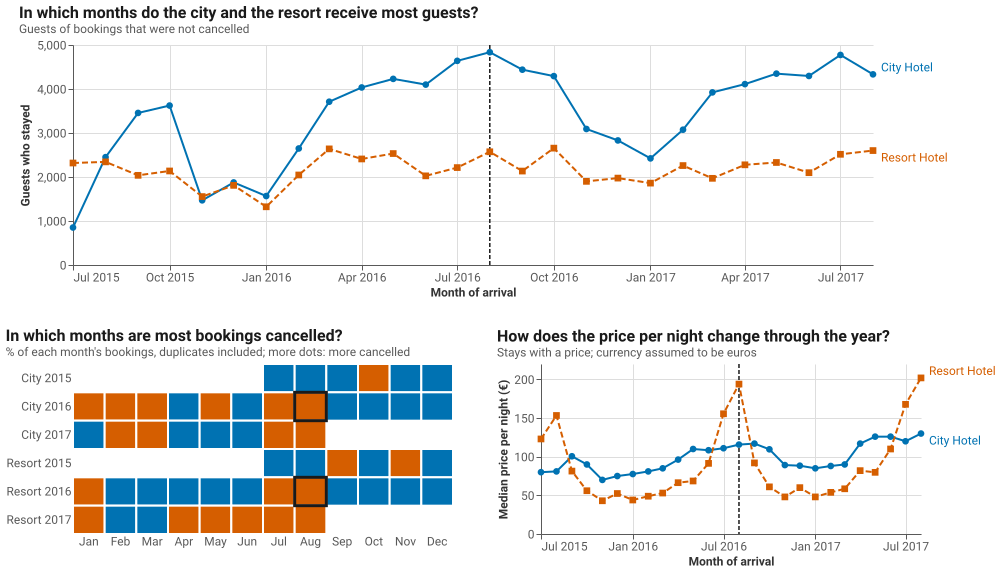

In [18]:
# ── Screen 1 as it will be laid out: C1 on top, C2 and C3 below ──────────────
# Shown with the month of August 2016 linked, to check that the rule appears in the three charts.
# (In the notebook the three charts share one set of parameters; on the page each chart is a separate
# embed and the page passes the values between them, task 6.5.)
p1, p2, p3 = screen_1_charts(pointer=False, sizes={'c1': (800, 220), 'c2': (380, 170), 'c3': (380, 170)})
linked_example = alt.param(name='linked_month', value='2016-08')
screen_1 = alt.vconcat(p1, alt.hconcat(p2, p3, spacing=40), spacing=30).add_params(*FILTER_PARAMS, linked_example)
dashboard_style(with_values(screen_1))

### Decision: encoding of the monthly charts

**Context:** Natalia (deuteranopia) must tell the two hotels apart in three charts and relate the same month across them. When the dashboard was refined, the students asked for a less usual chart for the cancellations (C2), whose colour must not be a continuous gradient.

**Decision taken:** two hues of the Okabe–Ito palette, blue for the City Hotel and vermillion for the Resort Hotel (with deuteranopia they stay blue and yellow, far apart), plus a different line style, a different point shape and a direct label for each hotel, so colour is never the only code. Points are kept on every month because they carry the tooltip, the `aria-label` and, in task 6.6, the keyboard focus. The y axes start at zero (honest scale, DRACO soft preference `zero_positional`). Lines, labels and the rule are hidden from screen readers (`aria=False`), so a screen reader meets only the points, each with a full sentence. The linked month is passed as a text key (`'2016-08'`), not as a time: while testing, the render engine and pandas turned the same month into times two hours apart (time zones), so the rule never matched.

**C2** is a calendar heatmap: one row per hotel and year and one column per calendar month, so the same month can be compared across years, which a line cannot do; its colour has seven named classes of ten points (ColorBrewer Purples, not a hotel colour), the page adds dots that grow denser with the class (pattern-rules skill), and the exact value is in the tooltip, the keyboard value box and the table.

**Alternatives considered:** for C2, diverging bars, a connected scatter of price and cancellations and a cycle plot (sketched for the students; the heatmap was chosen); a legend (rejected: it needs eye movement and memory, Part 4); points only on the hovered month (rejected: the keyboard needs a mark per month); y axes not starting at zero for the price (rejected: the price lines are far from zero, but DRACO's `zero_skew` only applies when the range is smaller than the distance to zero, which is not the case here).

> ⚠️ **Limitation:** the currency of `adr` is not stated in the paper; the charts say "currency assumed to be euros" (Part 1). The x axes of C2 and C3 are narrower than C1's, so a month is at the same relative place, not at the same pixel.

In [19]:
# ── Check 1: DRACO hard rules of C1, C2 and C3 ───────────────────────────────
draco_rows = []
COMPUTED_C2 = {'cancel_class': ('text', len(CANCEL_CLASSES)), 'month_number': ('number', 12), 'row_label': ('text', 6)}
for name, chart in [('C1', c1), ('C2', c2), ('C3', c3)]:
    draco_rows += draco_hard_rules(name, chart, month_hotel, COMPUTED_C2 if name == 'C2' else None)
draco_checks = pd.DataFrame(draco_rows)
print(f'{len(draco_checks)} rule checks on {draco_checks["chart"].nunique()} charts | all pass: {draco_checks["passes"].all()}')
draco_checks.pivot_table(index='hard rule', columns='chart', values='passes', aggfunc='all')

99 rule checks on 3 charts | all pass: True


chart,C1,C2,C3
hard rule,,,
color_with_cardinality_gt_twenty: 2 colours,True,NaN,True
color_with_cardinality_gt_twenty: 7 colours,NaN,True,NaN
enc_type_valid: x temporal on a date field,True,NaN,True
enc_type_valid: y quantitative on a numeric field,True,NaN,True
line_area_with_discrete: x and y not both discrete,True,NaN,True
line_area_without_x_y: has x and y,True,NaN,True
"no log scale (log_q, area_bar_with_log)",True,True,True
no_encodings: at least one encoding,True,True,True
point_tick_bar_without_x_or_y: has x or y,True,NaN,True


In [20]:
# ── Check 2: the numbers drawn equal the pandas table, for all 12 filter combinations ─
# Each chart is rendered by Vega (vl-convert) with the filters set as the page will set them. The aria-label
# of every point drawn is compared with a sentence written by pandas from month_hotel.
WORDS = {'guests': ('{:,}', 'guests'), 'cancel_rate': ('{:.1f}', '% of bookings cancelled'),
         'median_price': ('{:,.1f}', 'euros per night (median)')}
CHART_FIELDS = {'c1': 'guests', 'c2': 'cancel_rate', 'c3': 'median_price'}


def drawn_points(spec, hotel, year):
    """Sentences of the points Vega draws for one filter combination."""
    svg = vlc.vegalite_to_svg(with_params(spec, {'hotel_filter': hotel, 'year_filter': year}))
    return sorted(label for label in re.findall(r'aria-label="([^"]*)"', svg) if ' Hotel, ' in label)


def expected_points(field, hotel, year):
    """The same sentences written by pandas from the aggregated table."""
    number_format, words = WORDS[field]
    rows = filtered(month_hotel, hotel, year)
    return sorted(f"{row.hotel}, {row.arrival_month:%B %Y}: {number_format.format(getattr(row, field))} {words}"
                  for row in rows.itertuples())


value_checks = []
for name, field in CHART_FIELDS.items():
    for hotel in HOTEL_FILTERS:
        for year in YEAR_FILTERS:
            drawn, expected = drawn_points(SCREEN_1_SPECS[name], hotel, year), expected_points(field, hotel, year)
            value_checks.append({'chart': name.upper(), 'hotel filter': hotel, 'year filter': str(year),
                                 'points drawn': len(drawn), 'points expected': len(expected),
                                 'same values': drawn == expected})
value_checks = pd.DataFrame(value_checks)
print(f'{len(value_checks)} renders | points compared: {value_checks["points drawn"].sum():,} | '
      f'all equal to pandas: {value_checks["same values"].all()}')
value_checks.head(12)

36 renders | points compared: 624 | all equal to pandas: True


,chart,hotel filter,year filter,points drawn,points expected,same values
0,C1,Both,All,52,52,True
1,C1,Both,2015,12,12,True
2,C1,Both,2016,24,24,True
3,C1,Both,2017,16,16,True
4,C1,City Hotel,All,26,26,True
5,C1,City Hotel,2015,6,6,True
6,C1,City Hotel,2016,12,12,True
7,C1,City Hotel,2017,8,8,True
8,C1,Resort Hotel,All,26,26,True
9,C1,Resort Hotel,2015,6,6,True


In [21]:
# ── Check 3: the linked-month rule, and the chart filling its box ─────────────
# On the page each chart fills its box, so there is no fixed size to check here; the browser checks measure
# the page. The rule must be drawn once when a month is linked and not at all otherwise.

def rule_lines(svg):
    """Number of visible lines of the linked-month rule layer (the rules of the other months have opacity 0)."""
    group = re.search(r'<g class="mark-rule role-mark[^"]*"[^>]*?(/?)>', svg)
    if group is None or group.group(1) == '/':
        return 0
    lines = re.findall(r'<line[^>]*>', svg[group.end():svg.index('</g>', group.end())])
    return sum(1 for line in lines if 'opacity="0"' not in line)


size_checks = []
for name, spec in SCREEN_1_SPECS.items():
    svg = vlc.vegalite_to_svg(with_params(spec, {'linked_month': '2016-08'}))
    no_rule = vlc.vegalite_to_svg(with_params(spec, {}))
    # C2 (heatmap) marks the month with an outline (3 px) around its cells instead of a rule
    marks = (lambda svg: svg.count('stroke-width="3"')) if name == 'c2' else rule_lines
    size_checks.append({'chart': name.upper(), 'width and height': f"{spec['width']} x {spec['height']}",
                        'linked-month marks, August 2016 linked': marks(svg),
                        'linked-month marks, no month linked': marks(no_rule)})
size_checks = pd.DataFrame(size_checks)
size_checks

,chart,width and height,"linked-month marks, August 2016 linked","linked-month marks, no month linked"
0,C1,container x container,1,0
1,C2,container x container,2,0
2,C3,container x container,1,0


**Finding:** C1, C2 and C3 pass every DRACO hard rule that applies to their layers (line, point, text, rule and the heatmap's rect), and for all 12 hotel × year combinations every point and cell Vega draws carries exactly the value pandas computed. Each chart fills the box the page gives it; the linked month is marked once per hotel shown (a dashed rule in C1 and C3, outlined cells in C2) and not at all otherwise.

DRACO soft preferences: the quantitative measure is on y (position, the most accurate channel), time is on x, nothing is binned, the hotel (2 values) is on colour, line style and shape (cardinality well under 5), and the only text channel carries the hotel name (nominal), never a number. The line mark on a temporal x is DRACO's normal choice for an explicit time order.

### 5.3 Screen 2 (detail screen): C4 or the map C5, C9 and C7 + C8

The detail screen answers Q2 to Q6 with three chart areas that fit one 16:9 screen, without "Show more" (students' decision when the dashboard was refined; the cognitive-accessibility limit of 2–3 charts at once is kept by showing the dumbbell chart C4 and the map C5 in the same place, with a switch):

- **C4 dumbbell** (Q2): one row per country, one dot per hotel (City: blue circle, Resort: vermillion square), joined by a grey line, so the two mixes are compared in one chart; **C5 map** (Q2) in the same box;
- **C9 animated bubbles** (Q3 and Q6): one bubble per country for a calendar month, with x = median days booked in advance, y = % of the country's guests who arrive that month, size = guests that month; Play steps from January to December (course 07: time as a third dimension, with a Play button) and the selected country leaves a trail;
- **C7 and C8 box plots** (Q4 and Q6): nights per stay and days booked in advance for each country, side by side with the same country order.

They share the **selected country** (I7): by default **no country is selected**; a click on a dot, box, bubble or country (or the page's list) selects one, a second click or the "No country" button clears it. The selected country has a green band behind its row, a bold label, a bigger outlined dot, a green striped box, a green bubble with its trail and an outline on the map. A country outside the top 10, chosen in the list, is added at the top of C4, C7 and C8 and as a bubble in C9. They also share the **sort order** (I9) and the hotel and year filters (I1, I2).

In [22]:
# ── Shared parts of the screen 2 charts ───────────────────────────────────────
SELECTED_COLOUR = '#009E73'     # Okabe-Ito bluish green: 3.42:1 on white, 4.87:1 on the dark box; not a hotel colour
NEUTRAL = '#C8C8C8'             # bubbles of the other countries: light grey with a #595959 outline (7:1),
                                #   far from the green with deuteranopia; dark grey with a light outline at night
BOX_FILL = '#D9D9D9'            # boxes of the other countries (their outline gives the contrast)
RANGE_LINE = '#A6A6A6'          # line between the two dots of a country
OUTLINE = TEXT_MAIN
THEMES['dark'].update({BOX_FILL: '#4D4D4D', NEUTRAL: '#4D4D4D'})

selected_country = alt.param(name='selected_country', value='')         # '' = no country; a top-10 group, 'Other' or a country of the list
sort_order = alt.param(name='sort_order', value='guests')                 # 'guests' or 'alphabetical'
frame_month = alt.param(name='frame_month', value=1)                      # month shown by C9 (1 = January)
# A click on a mark: read by the page, which then sets selected_country in every chart of the screen
clicked_country = alt.selection_point(name='clicked_country', fields=['country_group'], on='click', empty=False)

MEDIANS_FILTER = 'datum.hotel_filter == hotel_filter && datum.year_filter == year_filter'
IS_SELECTED = 'datum.country_group == selected_country'
IN_VIEW = f'(datum.in_top || {IS_SELECTED})'      # the top 10 and Other, plus a country of the list if it is selected
# Sort key of the country rows: a selected country of the list first, then most guests first or alphabetical;
# 'Other' is always last
SORT_KEY = ("!datum.in_top ? (sort_order == 'guests' ? -1e13 : ' ') : "
            "datum.country_group == 'Other' ? (sort_order == 'guests' ? 1e12 : '~') : "
            "(sort_order == 'guests' ? -datum.country_guests : datum.country_group)")


def country_axis():
    """Country names on y, sorted by the toggle; the selected country's label is bold and darker."""
    return alt.Y('country_group:N', sort=alt.EncodingSortField(field='sort_key', op='min'),
                 axis=alt.Axis(title=None, labelLimit=150, labelFontSize=12, ticks=False, domain=False, labelOverlap=False,
                               labelFontWeight=alt.expr("datum.value == selected_country ? 'bold' : 'normal'"),
                               labelColor=alt.expr(f"datum.value == selected_country ? '{TEXT_MAIN}' : '{TEXT_SECONDARY}'")))


def selected_band(base):
    """A light green band behind the selected country's row, across the whole chart."""
    # One band per country, even where the table has one row per hotel
    return base.transform_filter(IS_SELECTED).transform_window(band_row='row_number()', groupby=['country_group']
    ).transform_filter('datum.band_row == 1').mark_rect(color=SELECTED_COLOUR, opacity=0.15, aria=False).encode(
        y=country_axis(), x=alt.value(0), x2=alt.value('width'))


def js_fixed(number, digits):
    """A number with a fixed number of decimals, rounded as JavaScript (and so Vega) rounds."""
    return str(Decimal(float(number)).quantize(Decimal(1).scaleb(-digits), rounding=ROUND_HALF_UP))


def js_trimmed(number):
    """Vega's '.1~f' format: one decimal, without a trailing zero (3 nights, 2.5 nights)."""
    return js_fixed(number, 1).rstrip('0').rstrip('.')

print('Sort key:', SORT_KEY)

Sort key: !datum.in_top ? (sort_order == 'guests' ? -1e13 : ' ') : datum.country_group == 'Other' ? (sort_order == 'guests' ? 1e12 : '~') : (sort_order == 'guests' ? -datum.country_guests : datum.country_group)


In [23]:
# ── C4: dumbbell chart of the guests by country, both hotels in one chart (Q2) ─

def c4_chart(clickable=True, width='container', height='container'):
    # Each hotel's total counts only the top 10 and Other (a country of the list is already inside Other)
    base = alt.Chart(alt.NamedData(name='country_hotel')).transform_filter(FILTER_EXPRESSION).transform_aggregate(
        guests='sum(guests)', groupby=['country_group', 'in_top', 'hotel']
    ).transform_calculate(counted='datum.in_top ? datum.guests : 0'
    ).transform_joinaggregate(hotel_guests='sum(counted)', groupby=['hotel']
    ).transform_joinaggregate(country_guests='sum(guests)', groupby=['country_group']
    ).transform_filter(IN_VIEW).transform_calculate(
        share='100 * datum.guests / datum.hotel_guests', sort_key=SORT_KEY,
        bar_text="datum.country_group + ', ' + datum.hotel + ': ' + format(datum.share, '.1f') + "
                 "' % of the guests of the hotel (' + format(datum.guests, ',d') + ' guests)'")
    x = alt.X('share:Q', title="% of the hotel's guests", axis=alt.Axis(format='d', tickCount=alt.expr('ceil(width / 70)')),
              scale=alt.Scale(zero=True))
    # Line between the two hotels of each country: its length is the difference between the two mixes
    line = base.transform_joinaggregate(min_share='min(share)', max_share='max(share)', groupby=['country_group']
    ).mark_rule(color=RANGE_LINE, strokeWidth=2, aria=False).encode(y=country_axis(), x='min_share:Q', x2='max_share:Q')
    legend = alt.Legend(title=None, orient='top', direction='horizontal', labelFontSize=12, symbolSize=110)
    dots = base.mark_point(filled=True, opacity=1).encode(
        y=country_axis(), x=x,
        color=alt.Color('hotel:N', scale=HOTEL_COLOURS, legend=legend),
        shape=alt.Shape('hotel:N', scale=HOTEL_SHAPES, legend=legend),
        size=alt.when(IS_SELECTED).then(alt.value(170)).otherwise(alt.value(100)),
        stroke=alt.when(IS_SELECTED).then(alt.value(OUTLINE)).otherwise(alt.value(CARD)),
        strokeWidth=alt.when(IS_SELECTED).then(alt.value(2)).otherwise(alt.value(1)),
        description=alt.Description('bar_text:N'),
        tooltip=[alt.Tooltip('country_group:N', title='Country'), alt.Tooltip('hotel:N', title='Hotel'),
                 alt.Tooltip('share:Q', title='Share of the guests of the hotel (%)', format='.1f'),
                 alt.Tooltip('guests:Q', title='Guests', format=',d')])
    if clickable:
        dots = dots.add_params(clicked_country)
    return alt.layer(selected_band(base), line, dots).properties(
        width=width, height=height,
        title=alt.TitleParams('Which countries do the guests come from?',
                              subtitle="Top 10 countries by guests, and Other: share of each hotel's guests"),
        description='Dumbbell chart of the share of guests from each of the ten main countries and Other, '
                    'one dot per hotel, with the selected country highlighted.')

c4 = c4_chart()
print('C4 built')

C4 built


In [24]:
# ── C9: animated bubbles, season and booking advance of each country (Q3, Q6) ─
MONTH_NAME = 'monthFormat(datum.calendar_month - 1)'


def c9_chart(clickable=True, width='container', height='container'):
    # The top 10 countries (not Other, a mix of markets) and the selected country if it is from the list
    base = alt.Chart(alt.NamedData(name='country_season')).transform_filter(MEDIANS_FILTER).transform_filter(
        f"datum.stays >= {MIN_STAYS} && ((datum.in_top && datum.country_group != 'Other') || {IS_SELECTED})"
    ).transform_calculate(is_selected=f'{IS_SELECTED} ? 1 : 0', month_name=MONTH_NAME)
    x = alt.X('median_lead_time:Q', title='Days booked ahead (median)', scale=alt.Scale(zero=True),
              axis=alt.Axis(tickCount=alt.expr('ceil(width / 70)')))
    y = alt.Y('share:Q', title='Arrivals (% of its year)', scale=alt.Scale(zero=True),
              axis=alt.Axis(format='d'))
    size = alt.Size('guests:Q', scale=alt.Scale(range=[40, 1400]), legend=None)
    this_month = 'datum.calendar_month == frame_month'

    # Every month of every country, invisible: it fixes the axes and the bubble sizes for the whole year,
    # so the bubbles move on the same scale while the animation plays
    frame = base.mark_circle(opacity=0, aria=False).encode(x=x, y=y, size=size)
    month_label = base.transform_filter(this_month).transform_aggregate(rows='count()', groupby=['month_name']
    ).mark_text(align='right', baseline='top', fontSize=28, fontWeight=600, color=TEXT_SECONDARY, aria=False
    ).encode(x=alt.value('width'), y=alt.value(0), text='month_name:N')
    # Trail of the months already shown: drawn for every country but visible only for the selected one, so the
    # layer is never empty when no country is selected (found in the browser: empty layers made Vega warn)
    trail = base.transform_filter('datum.calendar_month <= frame_month')
    visible = alt.when(IS_SELECTED).then(alt.value(1)).otherwise(alt.value(0))
    trail_colour = alt.when(IS_SELECTED).then(alt.value(SELECTED_COLOUR)).otherwise(alt.value(CARD))
    trail_line = trail.mark_line(strokeWidth=2, aria=False).encode(
        x=x, y=y, order='calendar_month:Q', detail='country_group:N', color=trail_colour,
        opacity=alt.when(IS_SELECTED).then(alt.value(0.8)).otherwise(alt.value(0)))
    trail_points = trail.mark_point(filled=True, fill=CARD, size=30, strokeWidth=1.5, aria=False).encode(
        x=x, y=y, stroke=trail_colour, opacity=visible)
    bubbles = base.transform_filter(this_month).transform_calculate(
        point_text="datum.country_group + ', ' + datum.month_name + ': ' + format(datum.share, '.1f') + "
                   "' % of its guests arrive this month, booked ' + format(datum.median_lead_time, '.1~f') + "
                   "' days ahead (median), ' + format(datum.guests, ',d') + ' guests'"
    ).mark_circle(opacity=0.85).encode(
        x=x, y=y, size=size, order=alt.Order('is_selected:Q'),
        color=alt.when(IS_SELECTED).then(alt.value(SELECTED_COLOUR)).otherwise(alt.value(NEUTRAL)),
        stroke=alt.when(IS_SELECTED).then(alt.value(OUTLINE)).otherwise(alt.value(TEXT_SECONDARY)),
        strokeWidth=alt.when(IS_SELECTED).then(alt.value(2.5)).otherwise(alt.value(1)),
        description=alt.Description('point_text:N'),
        tooltip=[alt.Tooltip('country_group:N', title='Country'), alt.Tooltip('month_name:N', title='Month'),
                 alt.Tooltip('share:Q', title="Arrivals this month (% of the market's year)", format='.1f'),
                 alt.Tooltip('median_lead_time:Q', title='Days booked in advance (median)', format='.1~f'),
                 alt.Tooltip('guests:Q', title='Guests this month', format=',d'),
                 alt.Tooltip('stays:Q', title='Stays this month', format=',d')])
    if clickable:
        bubbles = bubbles.add_params(clicked_country)
    # Names of the selected country and of the two countries with most guests that month
    labels = base.transform_filter(this_month).transform_window(
        guests_rank='rank()', sort=[alt.SortField('guests', order='descending')]
    ).transform_filter(f'datum.guests_rank <= 2 && !({IS_SELECTED})').mark_text(
        align='left', dx=9, dy=-9, fontSize=12, color=TEXT_MAIN, aria=False).encode(x=x, y=y, text='country_group:N')
    selected_label = base.transform_filter(this_month).mark_text(
        align='left', dx=9, dy=-9, fontSize=13, fontWeight='bold', color=TEXT_MAIN, aria=False).encode(
        x=x, y=y, text='country_group:N', opacity=alt.when(IS_SELECTED).then(alt.value(1)).otherwise(alt.value(0)))
    return alt.layer(frame, month_label, trail_line, trail_points, bubbles, labels, selected_label).properties(
        width=width, height=height,
        title=alt.TitleParams('When does each market travel, and how early does it book?',
                              subtitle=f'Top 10 countries; bubble size: guests that month; months under {MIN_STAYS} stays not drawn'),
        description='Animated bubble chart: for each calendar month, one bubble per country, placed by the median '
                    "days booked in advance and the share of the country's guests who arrive that month.")

c9 = c9_chart()
print('C9 built')

C9 built


In [25]:
# ── C7 and C8: box plots of the nights per stay and the days booked in advance (Q4, Q6) ─

def box_chart(prefix, axis_title, words, title, subtitle, description, clickable=True,
              width='container', height='container'):
    base = alt.Chart(alt.NamedData(name='country_medians')).transform_filter(
        f'{MEDIANS_FILTER} && {IN_VIEW} && isValid(datum.{prefix}_median)').transform_calculate(
        country_guests='datum.guests', sort_key=SORT_KEY,
        box_text=(f"datum.country_group + ': {words}, median ' + format(datum.{prefix}_median, '.1~f') + "
                  f"', middle half ' + format(datum.{prefix}_q1, '.1~f') + ' to ' + format(datum.{prefix}_q3, '.1~f') + "
                  f"', most stays ' + format(datum.{prefix}_low, '.1~f') + ' to ' + format(datum.{prefix}_high, '.1~f')"))
    x = alt.X(f'{prefix}_q1:Q', title=axis_title, axis=alt.Axis(format='d', tickCount=alt.expr('ceil(width / 70)')),
              scale=alt.Scale(zero=True))
    whisker = base.mark_rule(color=TEXT_SECONDARY, strokeWidth=1.5, aria=False).encode(
        y=country_axis(), x=alt.X(f'{prefix}_low:Q', title=axis_title), x2=f'{prefix}_high:Q')
    box = base.mark_bar(height={'band': 0.6}, strokeWidth=1.5, stroke=TEXT_SECONDARY).encode(
        y=country_axis(), x=x, x2=f'{prefix}_q3:Q',
        color=alt.when(IS_SELECTED).then(alt.value(SELECTED_COLOUR)).otherwise(alt.value(BOX_FILL)),
        description=alt.Description('box_text:N'),
        tooltip=[alt.Tooltip('country_group:N', title='Country'),
                 alt.Tooltip(f'{prefix}_median:Q', title=f'Median ({words})', format='.1~f'),
                 alt.Tooltip(f'{prefix}_q1:Q', title='Box from (first quartile)', format='.1~f'),
                 alt.Tooltip(f'{prefix}_q3:Q', title='Box to (third quartile)', format='.1~f'),
                 alt.Tooltip(f'{prefix}_low:Q', title='Line from', format='.1~f'),
                 alt.Tooltip(f'{prefix}_high:Q', title='Line to', format='.1~f'),
                 alt.Tooltip('guests:Q', title='Guests', format=',d')])
    if clickable:
        box = box.add_params(clicked_country)
    median = base.mark_tick(color=TEXT_MAIN, thickness=3, size=14, aria=False).encode(
        y=country_axis(), x=f'{prefix}_median:Q')
    return alt.layer(selected_band(base), whisker, box, median).properties(
        width=width, height=height, description=description, title=alt.TitleParams(title, subtitle=subtitle))


def screen_2_boxes(clickable=True, width='container', height='container'):
    c7 = box_chart('nights', 'Nights per stay', 'nights per stay',
                   'How long do guests from each market stay?',
                   'Box: middle half of the stays; thick mark: median; line: most stays',
                   'Box plot of the nights per stay for each country, with the selected country highlighted.',
                   clickable, width, height)
    c8 = box_chart('lead', 'Days booked in advance', 'days booked in advance',
                   'How far in advance does each market book?',
                   'Box: middle half of the stays; thick mark: median; line: most stays',
                   'Box plot of the days between booking and arrival for each country, with the selected country highlighted.',
                   clickable, width, height)
    return c7, c8

c7, c8 = screen_2_boxes()
print('C7 and C8 built')

C7 and C8 built


In [26]:
# ── C5: world map of guests per country (Q2), in the same box as C4 ──────────
WORLD_COUNTRIES = alt.NamedData(name='world', format=alt.DataFormat(type='topojson', feature='countries'))
ANTARCTICA = 10                                                        # ISO numeric code; 2 guests, but it takes a sixth of the map
MAP_CLASSES = ['1 to 9', '10 to 99', '100 to 999', '1,000 to 9,999', '10,000 or more']   # guests per country
MAP_BLUES = ['#D0E2FF', '#A6C8FF', '#4589FF', '#0043CE', '#002D9C']   # IBM Carbon blue 20 to 80: few to many guests
NO_GUESTS = '#EEEEEE'
# Night mode: the scale is reversed (the lightest blue is the most guests) and the countries without guests are dark grey
THEMES['dark'].update({light: dark for light, dark in zip(MAP_BLUES, MAP_BLUES[::-1])})
THEMES['dark'].update({NO_GUESTS: '#333333'})


def c5_chart(width='container', height='container'):
    background = alt.Chart(WORLD_COUNTRIES).transform_filter(f'datum.id != {ANTARCTICA}').mark_geoshape(
        fill=NO_GUESTS, stroke=CARD, strokeWidth=0.5, aria=False)
    countries = alt.Chart(alt.NamedData(name='country_map')).transform_filter(
        f'{FILTER_EXPRESSION} && datum.iso_numeric != {ANTARCTICA}').transform_aggregate(
        guests='sum(guests)', groupby=['iso_numeric', 'country_name']
    ).transform_lookup(lookup='iso_numeric', from_=alt.LookupData(data=WORLD_COUNTRIES, key='id'), as_='geo'
    ).transform_filter('isValid(datum.geo)').transform_calculate(
        map_text="datum.country_name + ': ' + format(datum.guests, ',d') + ' guests'",
        # Five classes, one per power of ten, so the legend can name each class in words
        guest_class=("datum.guests < 10 ? '1 to 9' : datum.guests < 100 ? '10 to 99' : datum.guests < 1000 ? "
                     "'100 to 999' : datum.guests < 10000 ? '1,000 to 9,999' : '10,000 or more'")
    ).mark_geoshape().encode(
        shape='geo:G',
        color=alt.Color('guest_class:O', scale=alt.Scale(domain=MAP_CLASSES, range=MAP_BLUES),
                        legend=alt.Legend(title='Guests per country', orient='right', labelLimit=200,
                                          symbolType='square', symbolSize=200, labelFontSize=12, titleFontSize=12)),
        stroke=alt.when('datum.country_name == selected_country').then(alt.value(SELECTED_COLOUR)).otherwise(alt.value(CARD)),
        strokeWidth=alt.when('datum.country_name == selected_country').then(alt.value(2.5)).otherwise(alt.value(0.5)),
        description=alt.Description('map_text:N'),
        tooltip=[alt.Tooltip('country_name:N', title='Country'), alt.Tooltip('guests:Q', title='Guests', format=',d')])
    return alt.layer(background, countries).project(type='equalEarth').properties(
        width=width, height=height, description='World map of the number of guests from each country, in five classes.',
        title=alt.TitleParams('Where do the guests come from?',
                              subtitle='Guests per country; grey: no guests; very small countries are not drawn'))

c5 = c5_chart()
print('C5 built')

C5 built


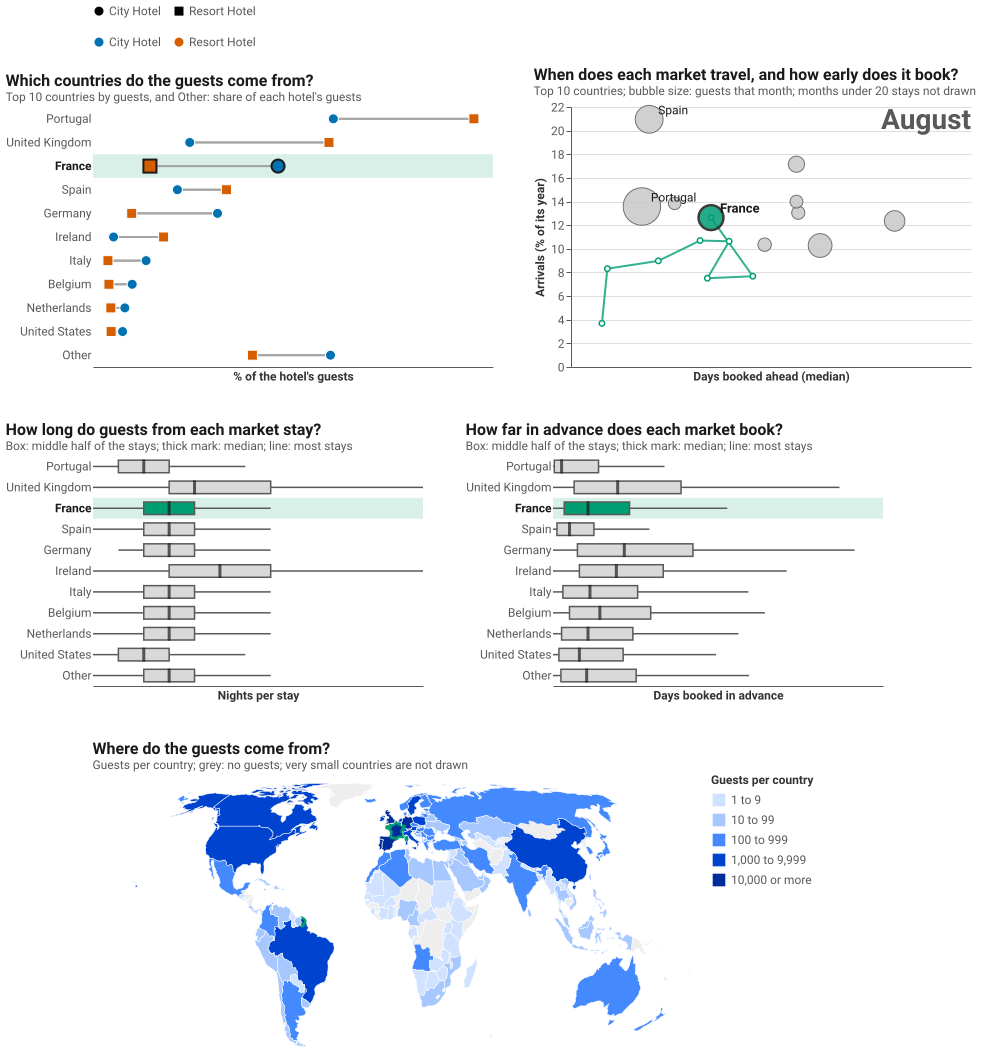

In [27]:
# ── Specs of screen 2 for the page, and the screen as it will be laid out ────
warnings.filterwarnings('ignore', message='Automatically deduplicated selection parameter')
SCREEN_2_SPECS = {
    'c4': dashboard_style(c4.add_params(*FILTER_PARAMS, selected_country, sort_order)).to_dict(),
    'c5': dashboard_style(c5.add_params(*FILTER_PARAMS, selected_country)).to_dict(),
    'c9': dashboard_style(c9.add_params(*FILTER_PARAMS, selected_country, frame_month)).to_dict(),
    'c7': dashboard_style(c7.add_params(*FILTER_PARAMS, selected_country, sort_order)).to_dict(),
    'c8': dashboard_style(c8.add_params(*FILTER_PARAMS, selected_country, sort_order)).to_dict(),
}
# Shown with France selected and August in C9, to check that the selection reaches every chart. Altair 6.2
# cannot add parameters to this concatenation (an internal naming error), so they are added to the spec directly.
p7, p8 = screen_2_boxes(clickable=False, width=330, height=230)
screen_2 = alt.vconcat(alt.hconcat(c4_chart(False, 400, 260), c9_chart(False, 400, 260), spacing=40),
                       alt.hconcat(p7, p8, spacing=40), c5_chart(600, 280), spacing=40
                       ).resolve_scale(color='independent', size='independent')
screen_2_preview = dashboard_style(screen_2).to_dict()
screen_2_preview['params'] = [{'name': 'hotel_filter', 'value': 'Both'}, {'name': 'year_filter', 'value': 'All'},
                              {'name': 'selected_country', 'value': 'France'}, {'name': 'sort_order', 'value': 'guests'},
                              {'name': 'frame_month', 'value': 8}]
screen_2_preview['datasets'] = DATASETS
SVG(vlc.vegalite_to_svg(screen_2_preview))

### Decision: encoding of the detail charts

**Context:** Natalia compares the mix of markets of the two destinations (Q2) and follows one market at a time (Q3, Q4, Q6); she has deuteranopia. The students asked for one screen without scrolling, one chart for both hotels, an animated chart that joins the months and the countries, and a box plot.

**Decision taken:** **C4** is a dumbbell chart: each country's share of the City Hotel's guests (blue circle) and of the Resort Hotel's guests (vermillion square) on one row, joined by a line whose length is the difference, so both mixes are compared by position on one axis. **C9** plays the year month by month (course 07, time as a third dimension): each country is a bubble placed by its median booking advance and by the share of its guests who arrive that month, so a market that travels in summer climbs in July and August and moves right as it books further ahead; the size (guests that month) only gives an approximate magnitude, as the data-viz skill allows. The selected country leaves a trail, so its path through the year stays visible (change blindness). **C7 and C8** are box plots, which show the spread of the stays and not only their median: the box holds the middle half of the stays, the thick mark the median and the line the stays within 1.5 box lengths (Tukey). The selected country is bluish green (`#009E73`, not a hotel colour) with a band behind its row, a bold label, an outline and, on the page, stripes and a text line. The map keeps Equal Earth and five classes, now in IBM Carbon's blue scale.

**Alternatives considered:** two bar panels for C4 (the old design; rejected by the students); bubbles per continent (rejected: the rest of the screen works with countries, so the selection could not be shared); medians as bars for C7 and C8 (the old design; the box plot shows more); the 4 charts at once (rejected: the cognitive-accessibility limit of 2–3 charts; the map shares C4's place).

> ⚠️ **Limitation:** "Other" mixes many markets, so its medians and season are less meaningful. Months with fewer than 20 stays of a country are not drawn in C9 (their median would be unstable); the table of the chart says so. Box plots hide the stays beyond the whiskers (the longest stays and the bookings made more than a year ahead). On the map, colour is the only code for the number of guests (the pattern rules keep quantitative maps without patterns); the tooltip and the data table give the numbers.

In [28]:
# ── Check 1: DRACO hard rules of C4, C5, C7, C8 and C9 ───────────────────────
COMPUTED_C4 = {'share': ('number', None), 'min_share': ('number', None), 'max_share': ('number', None)}
COMPUTED_C5 = {'guest_class': ('text', 5)}
COMPUTED_C9 = {'month_name': ('text', 12), 'is_selected': ('number', 2)}
draco_rows_2 = (draco_hard_rules('C4', c4, country_hotel, COMPUTED_C4)
                + draco_hard_rules('C9', c9, country_season, COMPUTED_C9)
                + draco_hard_rules('C7', c7, country_medians) + draco_hard_rules('C8', c8, country_medians)
                + draco_hard_rules('C5 (map, outside DRACO)', c5, country_map, COMPUTED_C5))
draco_checks = pd.concat([draco_checks, pd.DataFrame(draco_rows_2)], ignore_index=True)
screen_2_draco = draco_checks[draco_checks['chart'].isin(['C4', 'C5 (map, outside DRACO)', 'C7', 'C8', 'C9'])]
print(f'{len(screen_2_draco)} rule checks on screen 2 | all pass: {screen_2_draco["passes"].all()} '
      f'| all charts so far: {draco_checks["passes"].all()}')
screen_2_draco.pivot_table(index='hard rule', columns='chart', values='passes', aggfunc='all').fillna('-')

140 rule checks on screen 2 | all pass: True | all charts so far: True


chart,C4,"C5 (map, outside DRACO)",C7,C8,C9
hard rule,,,,,
bar_area_without_zero: the continuous axis includes zero,-,-,True,True,-
bar_tick_continuous_x_y: not continuous on both x and y,-,-,True,True,-
color_with_cardinality_gt_twenty: 2 colours,True,-,-,-,-
color_with_cardinality_gt_twenty: 5 colours,-,True,-,-,-
enc_type_valid: order quantitative on a numeric field,-,-,-,-,True
enc_type_valid: size quantitative on a numeric field,-,-,-,-,True
enc_type_valid: x quantitative on a numeric field,True,-,True,True,True
enc_type_valid: y quantitative on a numeric field,-,-,-,-,True
line_area_with_discrete: x and y not both discrete,-,-,-,-,True


In [29]:
# ── Contrast of the colours in both themes, and distance between them with simulated deuteranopia ─
# Same method as Part 4 (WCAG relative luminance; Machado et al. 2009 matrix, severity 1; CIELAB distance)
def linear_rgb(hex_colour):
    channels = pd.Series([int(hex_colour[i:i + 2], 16) / 255 for i in (1, 3, 5)])
    return channels.where(channels > 0.04045, channels / 12.92).where(channels <= 0.04045, ((channels + 0.055) / 1.055) ** 2.4)

def contrast(colour_a, colour_b='#FFFFFF'):
    lum = [0.2126 * c[0] + 0.7152 * c[1] + 0.0722 * c[2] for c in (linear_rgb(colour_a), linear_rgb(colour_b))]
    return (max(lum) + 0.05) / (min(lum) + 0.05)

DEUTERANOPIA = [[0.367322, 0.860646, -0.227968], [0.280085, 0.672501, 0.047413], [-0.011820, 0.042940, 0.968881]]

def lab_deuteranopia(hex_colour):
    rgb = linear_rgb(hex_colour)
    sim = [min(max(sum(DEUTERANOPIA[r][c] * rgb[c] for c in range(3)), 0), 1) for r in range(3)]
    xyz = [sum(m * v for m, v in zip(row, sim)) for row in [[0.4124, 0.3576, 0.1805], [0.2126, 0.7152, 0.0722], [0.0193, 0.1192, 0.9505]]]
    xyz = [v / w for v, w in zip(xyz, [0.95047, 1.0, 1.08883])]
    f = [v ** (1 / 3) if v > 0.008856 else 7.787 * v + 16 / 116 for v in xyz]
    return (116 * f[1] - 16, 500 * (f[0] - f[1]), 200 * (f[1] - f[2]))

def distance_deuteranopia(colour_a, colour_b):
    return sum((a - b) ** 2 for a, b in zip(lab_deuteranopia(colour_a), lab_deuteranopia(colour_b))) ** 0.5

dark = lambda colour: THEMES['dark'].get(colour, colour)
DARK_CARD = dark(CARD)
colour_rows = []
for use, colour, other_use, other in [('City Hotel', CITY_COLOUR, 'Resort Hotel', RESORT_COLOUR),
                                      ('Resort Hotel', RESORT_COLOUR, 'City Hotel', CITY_COLOUR),
                                      ('Selected country', SELECTED_COLOUR, 'fill of the other bubbles', NEUTRAL),
                                      ('Selected country', SELECTED_COLOUR, 'City Hotel', CITY_COLOUR),
                                      ('Outline of the other bubbles', TEXT_SECONDARY, 'selected country', SELECTED_COLOUR)]:
    for theme, card, convert in [('light', CARD, lambda c: c), ('dark', DARK_CARD, dark)]:
        colour_rows.append({'use': use, 'theme': theme, 'hex': convert(colour),
                            'contrast on the chart box': round(contrast(convert(colour), card), 2),
                            'compared with': other_use,
                            'CIELAB distance with deuteranopia': round(distance_deuteranopia(convert(colour), convert(other)), 1)})
colour_checks = pd.DataFrame(colour_rows)
colour_checks['passes 3:1'] = colour_checks['contrast on the chart box'] >= 3
print('Every data colour passes 3:1 in both themes:', colour_checks['passes 3:1'].all())
colour_checks

Every data colour passes 3:1 in both themes: True


,use,theme,hex,contrast on the chart box,compared with,CIELAB distance with deuteranopia,passes 3:1
0,City Hotel,light,#0072B2,5.19,Resort Hotel,108.4,True
1,City Hotel,dark,#56B4E9,7.22,Resort Hotel,111.4,True
2,Resort Hotel,light,#D55E00,3.87,City Hotel,108.4,True
3,Resort Hotel,dark,#E69F00,7.40,City Hotel,111.4,True
4,Selected country,light,#009E73,3.42,fill of the other bubbles,26.5,True
5,Selected country,dark,#009E73,4.87,fill of the other bubbles,24.9,True
6,Selected country,light,#009E73,3.42,City Hotel,55.7,True
7,Selected country,dark,#009E73,4.87,City Hotel,48.9,True
8,Outline of the other bubbles,light,#595959,7.00,selected country,20.3,True
9,Outline of the other bubbles,dark,#B3B3B3,7.95,selected country,19.5,True


In [30]:
# ── Check 2: the numbers drawn equal pandas, for every filter combination ────

def drawn_labels(spec, params, pattern):
    """aria-labels of the marks Vega draws with some parameters set, keeping those that match a pattern."""
    svg = vlc.vegalite_to_svg(with_params(spec, params))
    return sorted(label for label in re.findall(r'aria-label="([^"]*)"', svg) if re.search(pattern, label))


def expected_c4(hotel, year, selected=''):
    rows = filtered(country_hotel, hotel, year).groupby(['country_group', 'in_top', 'hotel'], as_index=False)['guests'].sum()
    totals = rows[rows['in_top']].groupby('hotel')['guests'].sum()
    rows = rows[rows['in_top'] | (rows['country_group'] == selected)]
    return sorted(f"{r.country_group}, {r.hotel}: {js_fixed(100 * r.guests / totals[r.hotel], 1)} % of the guests of the hotel ({r.guests:,} guests)"
                  for r in rows.itertuples())


def expected_box(prefix, words, hotel, year, selected=''):
    rows = country_medians[(country_medians['hotel_filter'] == hotel) & (country_medians['year_filter'] == str(year))
                           & (country_medians['in_top'] | (country_medians['country_group'] == selected))
                           & country_medians[prefix + '_median'].notna()]
    return sorted(f"{r.country_group}: {words}, median {js_trimmed(getattr(r, prefix + '_median'))}, middle half "
                  f"{js_trimmed(getattr(r, prefix + '_q1'))} to {js_trimmed(getattr(r, prefix + '_q3'))}, most stays "
                  f"{js_trimmed(getattr(r, prefix + '_low'))} to {js_trimmed(getattr(r, prefix + '_high'))}"
                  for r in rows.itertuples())


def expected_c9(hotel, year, month, selected=''):
    rows = country_season[(country_season['hotel_filter'] == hotel) & (country_season['year_filter'] == str(year))
                          & (country_season['calendar_month'] == month) & (country_season['stays'] >= MIN_STAYS)
                          & ((country_season['in_top'] & (country_season['country_group'] != 'Other'))
                             | (country_season['country_group'] == selected))]
    return sorted(f"{r.country_group}, {calendar.month_name[month]}: {js_fixed(r.share, 1)} % of its guests arrive this "
                  f"month, booked {js_trimmed(r.median_lead_time)} days ahead (median), {r.guests:,} guests"
                  for r in rows.itertuples())


world_ids = {country['id'] for country in WORLD['objects']['countries']['geometries']}

def expected_c5(hotel, year):
    rows = filtered(country_map, hotel, year).groupby(['iso_numeric', 'country_name'], as_index=False)['guests'].sum()
    rows = rows[rows['iso_numeric'].isin(world_ids) & (rows['iso_numeric'] != ANTARCTICA)]
    return sorted(f"{r.country_name}: {r.guests:,} guests" for r in rows.itertuples())


value_rows = []
for hotel in HOTEL_FILTERS:
    for year in YEAR_FILTERS:
        filters = {'hotel_filter': hotel, 'year_filter': year}
        cases = [('C4', drawn_labels(SCREEN_2_SPECS['c4'], filters, r'% of the guests of the hotel'), expected_c4(hotel, year)),
                 ('C7', drawn_labels(SCREEN_2_SPECS['c7'], filters, r': nights per stay, median '),
                  expected_box('nights', 'nights per stay', hotel, year)),
                 ('C8', drawn_labels(SCREEN_2_SPECS['c8'], filters, r': days booked in advance, median '),
                  expected_box('lead', 'days booked in advance', hotel, year)),
                 ('C5', drawn_labels(SCREEN_2_SPECS['c5'], filters, r'^[^;]*: [\d,]+ guests$'), expected_c5(hotel, year))]
        # C9: every month the year filter keeps
        months = sorted(country_season.query("hotel_filter == @hotel and year_filter == @year_text",
                                             local_dict={'hotel': hotel, 'year_text': str(year)})['calendar_month'].unique())
        for month in months:
            cases.append((f'C9 (month {month:02d})', drawn_labels(SCREEN_2_SPECS['c9'], {**filters, 'frame_month': int(month)},
                                                                 r'% of its guests arrive this month'),
                          expected_c9(hotel, year, month)))
        # A country of the list (Brazil) selected: it is added to C4, C7, C8 and C9
        brazil = {**filters, 'selected_country': 'Brazil'}
        cases += [('C4 (Brazil selected)', drawn_labels(SCREEN_2_SPECS['c4'], brazil, r'% of the guests of the hotel'),
                   expected_c4(hotel, year, 'Brazil')),
                  ('C7 (Brazil selected)', drawn_labels(SCREEN_2_SPECS['c7'], brazil, r': nights per stay, median '),
                   expected_box('nights', 'nights per stay', hotel, year, 'Brazil')),
                  ('C9 (Brazil selected, August)', drawn_labels(SCREEN_2_SPECS['c9'], {**brazil, 'frame_month': 8},
                                                               r'% of its guests arrive this month'),
                   expected_c9(hotel, year, 8, 'Brazil') if 8 in months else [])]
        for chart, drawn, expected in cases:
            value_rows.append({'chart': chart, 'hotel filter': hotel, 'year filter': str(year), 'points drawn': len(drawn),
                               'points expected': len(expected), 'same values': drawn == expected})
screen_2_values = pd.DataFrame(value_rows)
value_checks = pd.concat([value_checks, screen_2_values], ignore_index=True)
print(f'{len(screen_2_values)} renders | marks compared: {screen_2_values["points drawn"].sum():,} | '
      f'all equal to pandas: {screen_2_values["same values"].all()}')
screen_2_values.assign(chart=screen_2_values['chart'].str[:2]).groupby('chart')[['points drawn', 'same values']].agg(
    {'points drawn': 'sum', 'same values': 'all'})

198 renders | marks compared: 3,118 | all equal to pandas: True


,points drawn,same values
chart,,
C4,368,True
C5,1222,True
C7,276,True
C8,132,True
C9,1120,True


In [31]:
# ── Check 3: selection, sort order and the animation frame ────────────────────

def axis_countries(svg):
    """Country names of the first y axis, in the order they are drawn (top to bottom)."""
    for group in re.findall(r'<g class="mark-text role-axis-label"[^>]*>(.*?)</g>', svg, flags=re.S):
        names = re.findall(r'>([^<]+)</text>', group)
        if names and set(names) <= set(TOP_10 + ['Other'] + MORE_COUNTRIES):
            return names
    return []


guests_order = (country_hotel[country_hotel['in_top']].groupby('country_group')['guests'].sum().drop('Other')
                .sort_values(ascending=False).index.tolist() + ['Other'])
alphabetical_order = sorted(TOP_10) + ['Other']
selection_rows = []
for name in ['c4', 'c7', 'c8']:
    for order, expected in [('guests', guests_order), ('alphabetical', alphabetical_order)]:
        svg = vlc.vegalite_to_svg(with_params(SCREEN_2_SPECS[name], {'sort_order': order}))
        selection_rows.append({'chart': name.upper(), 'check': f'order "{order}" (both hotels, all years)',
                               'passes': axis_countries(svg) == expected})
        svg = vlc.vegalite_to_svg(with_params(SCREEN_2_SPECS[name], {'sort_order': order, 'selected_country': 'Brazil'}))
        selection_rows.append({'chart': name.upper(), 'check': f'order "{order}", Brazil selected: Brazil first, then the same order',
                               'passes': axis_countries(svg) == ['Brazil'] + expected})
    svg = vlc.vegalite_to_svg(with_params(SCREEN_2_SPECS[name], {}))
    selection_rows.append({'chart': name.upper(), 'check': 'no country selected (default): no green and no outline',
                           'passes': f'fill="{SELECTED_COLOUR}"' not in svg and f'stroke="{OUTLINE}"' not in svg})
for country in ['France', 'Other']:
    svg = vlc.vegalite_to_svg(with_params(SCREEN_2_SPECS['c4'], {'selected_country': country}))
    selection_rows.append({'chart': 'C4', 'check': f'{country} selected: 2 outlined dots and 1 band',
                           'passes': svg.count(f'stroke="{OUTLINE}"') == 2 and svg.count(f'fill="{SELECTED_COLOUR}"') == 1})
    for name in ['c7', 'c8']:
        svg = vlc.vegalite_to_svg(with_params(SCREEN_2_SPECS[name], {'selected_country': country}))
        selection_rows.append({'chart': name.upper(), 'check': f'{country} selected: 1 green box and 1 band',
                               'passes': svg.count(f'fill="{SELECTED_COLOUR}"') == 2})
svg = vlc.vegalite_to_svg(with_params(SCREEN_2_SPECS['c9'], {'frame_month': 8}))
selection_rows.append({'chart': 'C9', 'check': 'no country selected, August: 10 bubbles (the top 10, not Other), no green',
                       'passes': len(re.findall(r'aria-label="[^"]*arrive this month', svg)) == 10 and f'fill="{SELECTED_COLOUR}"' not in svg})
svg = vlc.vegalite_to_svg(with_params(SCREEN_2_SPECS['c9'], {'selected_country': 'Brazil', 'frame_month': 8}))
selection_rows.append({'chart': 'C9', 'check': 'Brazil selected, August: 11 bubbles, Brazil green',
                       'passes': len(re.findall(r'aria-label="[^"]*arrive this month', svg)) == 11 and svg.count(f'fill="{SELECTED_COLOUR}"') == 1
                                 and 'aria-label="Brazil, August' in svg})
svg = vlc.vegalite_to_svg(with_params(SCREEN_2_SPECS['c9'], {'selected_country': 'France', 'frame_month': 8}))
selection_rows.append({'chart': 'C9', 'check': 'France selected, August: 1 green bubble, a trail of 8 months, "August" written',
                       'passes': svg.count(f'fill="{SELECTED_COLOUR}"') == 1 and svg.count(f'stroke="{SELECTED_COLOUR}"') == 9
                                 and '>August</text>' in svg})
svg = vlc.vegalite_to_svg(with_params(SCREEN_2_SPECS['c5'], {'selected_country': 'France'}))
selection_rows.append({'chart': 'C5', 'check': 'France selected: one country outlined in green',
                       'passes': svg.count(f'stroke="{SELECTED_COLOUR}"') == 1})
selection_checks = pd.DataFrame(selection_rows)
print('All selection, sort and frame checks pass:', selection_checks['passes'].all())
selection_checks

All selection, sort and frame checks pass: True


,chart,check,passes
0,C4,"order ""guests"" (both hotels, all years)",True
1,C4,"order ""guests"", Brazil selected: Brazil first,...",True
2,C4,"order ""alphabetical"" (both hotels, all years)",True
3,C4,"order ""alphabetical"", Brazil selected: Brazil ...",True
4,C4,no country selected (default): no green and no...,True
5,C7,"order ""guests"" (both hotels, all years)",True
6,C7,"order ""guests"", Brazil selected: Brazil first,...",True
7,C7,"order ""alphabetical"" (both hotels, all years)",True
8,C7,"order ""alphabetical"", Brazil selected: Brazil ...",True
9,C7,no country selected (default): no green and no...,True


In [32]:
# ── Check 4: every chart fills its box, and what the map cannot draw ─────────
size_rows = [{'chart': name.upper(), 'width and height': f"{spec['width']} x {spec['height']}"}
             for name, spec in SCREEN_2_SPECS.items()]
size_checks = pd.concat([size_checks, pd.DataFrame(size_rows)], ignore_index=True)

# Countries and guests the map cannot draw (too small for the 1:110 million map)
not_drawn = country_map[~country_map['iso_numeric'].isin(world_ids) | (country_map['iso_numeric'] == ANTARCTICA)]
print(f"Not drawn on the map: {not_drawn['country'].nunique()} countries (Antarctica and very small ones), "
      f"{not_drawn['guests'].sum():,} guests ({100 * not_drawn['guests'].sum() / country_map['guests'].sum():.2f} % "
      f"of the guests with a known country)")
pd.DataFrame(size_rows)

Not drawn on the map: 29 countries (Antarctica and very small ones), 190 guests (0.13 % of the guests with a known country)


,chart,width and height
0,C4,container x container
1,C5,container x container
2,C9,container x container
3,C7,container x container
4,C8,container x container


**Finding:** C4, C7, C8 and C9 pass every DRACO hard rule that applies; the map only has the general rules, as DRACO has none for maps. For every filter combination, every month of C9 included, and with a country of the list (Brazil) selected, every dot, box, bubble and country Vega draws carries exactly the value pandas computed; by default nothing is highlighted. The selection reaches every chart, the sort toggle gives the expected orders, C9 draws the selected country's trail up to the month shown, and every data colour passes 3:1 on its box in both themes.

DRACO soft preferences: the measures are on position (x for the dots and boxes, x and y for the bubbles); the country axis has 11 values, under the soft limit of 12; rows are sorted; nothing is binned; the two hotels use colour and shape (2 values each); size is only a secondary channel in C9.

## 6. Export

In [33]:
# ── Export the aggregated tables to data/processed ───────────────────────────
tables = {'dashboard_month_hotel.csv': month_hotel, 'dashboard_country_hotel.csv': country_hotel,
          'dashboard_country_map.csv': country_map, 'dashboard_filter_kpis.csv': filter_kpis,
          'dashboard_country_medians.csv': country_medians, 'dashboard_country_season.csv': country_season}
for file_name, table in tables.items():
    table.to_csv(PROCESSED_DIR / file_name, index=False)
checks.to_csv(OUTPUT_DIR / 'table_checks.csv', index=False)
top_10_table.to_csv(OUTPUT_DIR / 'top_10_countries.csv')

# Read them back to check that they load, with their size
pd.DataFrame([(name, len(pd.read_csv(PROCESSED_DIR / name)), round((PROCESSED_DIR / name).stat().st_size / 1024, 1))
              for name in tables], columns=['file', 'rows', 'KB'])

,file,rows,KB
0,dashboard_month_hotel.csv,52,3.0
1,dashboard_country_hotel.csv,360,13.3
2,dashboard_country_map.csv,586,21.1
3,dashboard_filter_kpis.csv,12,0.8
4,dashboard_country_medians.csv,768,61.4
5,dashboard_country_season.csv,5537,250.1


In [34]:
# ── Export the chart checks and a preview image of the charts of each screen ─
draco_checks.to_csv(OUTPUT_DIR / 'draco_checks.csv', index=False)
value_checks.to_csv(OUTPUT_DIR / 'chart_value_checks.csv', index=False)
size_checks.to_csv(OUTPUT_DIR / 'chart_size_checks.csv', index=False)
selection_checks.to_csv(OUTPUT_DIR / 'selection_sort_checks.csv', index=False)
colour_checks.to_csv(OUTPUT_DIR / 'selected_colour_checks.csv', index=False)
for file_name, preview in [('screen_1_charts.png', dashboard_style(with_values(screen_1)).to_dict()),
                           ('screen_2_charts.png', screen_2_preview)]:
    (OUTPUT_DIR / file_name).write_bytes(vlc.vegalite_to_png(preview, scale=2))
sorted(path.name for path in OUTPUT_DIR.iterdir())

['chart_size_checks.csv',
 'chart_value_checks.csv',
 'draco_checks.csv',
 'export_checks.csv',
 'screen_1_charts.png',
 'screen_2_charts.png',
 'selected_colour_checks.csv',
 'selection_sort_checks.csv',
 'table_checks.csv',
 'top_10_countries.csv']

In [35]:
# ── Export data.js and specs.js for the dashboard pages (task 6.4) ───────────
# The pages load these two files with <script src>, so they open by double-click with no server
# (architecture.md). Only the columns that the charts and the KPIs use are kept.
DASHBOARD_TABLES = {
    'month_hotel': month_hotel[['arrival_month', 'hotel', 'year', 'bookings', 'cancelled', 'stays', 'guests',
                                'cancel_rate', 'median_price']],
    'country_hotel': country_hotel[['country_group', 'in_top', 'hotel', 'year', 'guests']],
    'country_medians': country_medians.drop(columns=['median_nights', 'median_lead_time']),   # same as nights_median, lead_median
    # Only the months that can be drawn (at least 20 stays); the shares were computed on all months
    'country_season': country_season.loc[country_season['stays'] >= MIN_STAYS,
                                         ['hotel_filter', 'year_filter', 'country_group', 'in_top', 'calendar_month',
                                          'stays', 'guests', 'share', 'median_lead_time']],
    'country_map': country_map[['iso_numeric', 'country_name', 'hotel', 'year', 'guests']].astype({'iso_numeric': int}),
    'filter_kpis': filter_kpis,
}
dashboard_data = {name: records(table) for name, table in DASHBOARD_TABLES.items()}
dashboard_data['world'] = WORLD
dashboard_specs = {**SCREEN_1_SPECS, **SCREEN_2_SPECS}


def write_js(path, constants, what):
    """Write values as JavaScript constants (JSON), so a page can load them with <script src>."""
    text = f'// {what}\n// Written by Part 6/code/build_dashboard.ipynb; do not edit by hand.\n'
    for variable, value in constants.items():
        text += f'const {variable} = {json.dumps(value, ensure_ascii=False, separators=(",", ":"), allow_nan=False)};\n'
    path.write_text(text, encoding='utf-8')
    return path


write_js(DASHBOARD_DIR / 'data.js', {'DASHBOARD_DATA': dashboard_data},
         'Aggregated data of the hotel bookings dashboard and the world map (TopoJSON).')
# The night-mode colours go first, so the specs are the last constant of the file
write_js(DASHBOARD_DIR / 'specs.js', {'DASHBOARD_THEMES': THEMES, 'DASHBOARD_SPECS': dashboard_specs},
         'Night-mode colours and Vega-Lite specs of the dashboard charts; their named datasets are in data.js.')
pd.DataFrame([(path.name, round(path.stat().st_size / 1024, 1)) for path in [DASHBOARD_DIR / 'data.js', DASHBOARD_DIR / 'specs.js']],
             columns=['file', 'KB'])

,file,KB
0,data.js,741.0
1,specs.js,51.1


In [36]:
# ── Check: the exported files give the same charts as the notebook ───────────
# Each spec is read back from specs.js, given only the columns kept in data.js, and drawn by Vega;
# the aria-labels of its marks must be the same as with the full tables used in the checks above.

def read_js(path, variable):
    text = path.read_text(encoding='utf-8')
    return json.loads(text.split(f'const {variable} = ', 1)[1].rstrip().rstrip(';'))


exported_data = read_js(DASHBOARD_DIR / 'data.js', 'DASHBOARD_DATA')
exported_specs = read_js(DASHBOARD_DIR / 'specs.js', 'DASHBOARD_SPECS')
export_rows = []
for name, spec in exported_specs.items():
    full = vlc.vegalite_to_svg(with_params(spec, {}))
    reduced = json.loads(json.dumps(spec))
    reduced['datasets'] = exported_data
    reduced = vlc.vegalite_to_svg(reduced)
    labels = lambda svg: sorted(re.findall(r'aria-label="([^"]*)"', svg))
    export_rows.append({'chart': name.upper(), 'marks with a label': len(labels(reduced)),
                        'same as in the notebook': labels(full) == labels(reduced)})
export_checks = pd.DataFrame(export_rows)
print('Charts in specs.js:', len(exported_specs), '| datasets in data.js:', sorted(exported_data),
      '| all the same:', export_checks['same as in the notebook'].all())
export_checks.to_csv(OUTPUT_DIR / 'export_checks.csv', index=False)
export_checks

Charts in specs.js: 8 | datasets in data.js: ['country_hotel', 'country_map', 'country_medians', 'country_season', 'filter_kpis', 'month_hotel', 'world'] | all the same: True


,chart,marks with a label,same as in the notebook
0,C1,56,True
1,C2,57,True
2,C3,56,True
3,C4,27,True
4,C5,139,True
5,C9,14,True
6,C7,15,True
7,C8,15,True


### Decision: how the pages get the data, the specs and the libraries

**Context:** the dashboard must open by double-click, with no server and no internet (architecture.md); browsers block `fetch` of a local `.json` file.

**Decision taken:** the notebook writes `data.js` (`const DASHBOARD_DATA = {...}`, size above, world map included) and `specs.js` (`const DASHBOARD_THEMES` with the night-mode colours and `const DASHBOARD_SPECS = {...}`), loaded with `<script src>`. Each spec keeps its named datasets, and the page adds their values before drawing (`dashboard.js`). The libraries are local copies from npm: Vega 6.2.0, Vega-Lite 6.4.1 (the version Altair 6.2.2 writes) and vega-embed 7.1.0, with their BSD-3-Clause licences, in `dashboard/lib/`. The page style and code shared by both screens are in `dashboard.css` and `dashboard.js`, so the two screens cannot drift apart.

**Alternatives considered:** one HTML file with the data inline (rejected by the skills: data and specs stay out of the HTML); loading the libraries from a CDN (rejected: no internet needed).

> ⚠️ **Limitation:** `dashboard.css` and `dashboard.js` are two files more than the list in architecture.md; they hold no data.

## Conclusions

### Task 6.1 (data preparation)
1. Six aggregated tables replace the 119,201 rows (sizes in section 6); every one adds up to the cleaned data, and the precomputed medians match a direct calculation.
2. Every Part 5 interaction can work on them: the hotel and year filters (all tables keep `hotel` and `year`, or have one row per filter combination), the month highlight (monthly rows) and the country selection (country groups).
3. Counting visitors (guests of stays) instead of bookings changes the country picture: Portugal falls from 40.7 % of bookings to 25.8 % of guests.

### Task 6.2 (charts of screen 1)
1. C1 and C3 are built by one function and C2 (calendar heatmap, colour in seven classes) by another, on the named dataset `month_hotel`, with the filters, the linked month and the tooltips as parameters of the spec; each fills its box on the page.
2. They pass every applicable DRACO hard rule, and for all 12 filter combinations the values Vega draws equal the pandas table.
3. Colour is never the only code: each hotel has its own hue, line style, point shape and direct label.

### Task 6.3 (charts of screen 2)
1. C4 (dumbbell: share of each hotel's guests by country), the map C5 (in the same box as C4), C9 (animated bubbles: season and booking advance per month) and C7, C8 (box plots of the nights and the booking advance) are built on the named datasets `country_hotel`, `country_map`, `world`, `country_season` and `country_medians`; a country outside the top 10 can be added from the page's list.
2. They pass every applicable DRACO hard rule (the map is outside DRACO), and for all 12 filter combinations (and every month of C9) the values drawn equal pandas.
3. The selected country is shown by colour (bluish green), a band behind its row, an outline, a bold label and, on the page, text; the sort toggle keeps "Other" last.

### Task 6.4 (export)
1. `data.js` and `specs.js` are written into `../dashboard/`; read back and drawn again, the eight charts give exactly the same marks as in the notebook.
2. The pages that use them are checked in a browser in `browser_checks.ipynb`.

### Task 6.5 (interactions)
1. The specs keep the parameters that the page changes (filters, linked month, selected country, sort order); the pointer selection of C1-C3 sits on an invisible copy of the points, because Vega-Lite 6.4.1 wrote "undefined" for the hotel in the tooltip of its nearest-point layer.
2. C9 has a `frame_month` parameter that the page's Play button and slider change; the checks of the interactions are in `browser_checks.ipynb`.

### Limitations
- Duplicated rows are kept (cleaning rule 1); C2 says so in its subtitle and the dashboard adds a note.
- The currency of the price is assumed to be euros.
- "Other" mixes many markets, so its medians are less meaningful; very small countries are not drawn on the 1:110 million map.
- In the notebook the charts of a screen share their parameters; on the page each chart is a separate embed, so passing the linked month and the selected country between them is JavaScript (task 6.5).

### Next steps
- Done in the next tasks: the keyboard and focus layer, the text alternatives and the help page are in `../dashboard/dashboard.js` and `accessibility.html`, checked in a browser in `browser_checks.ipynb` (tasks 6.5 to 6.7); the screenshots and the review of the four checklists are in `final_review.ipynb` (task 6.8).